## C1 · Matplotlib: plotting basics

Line plots, styles, labels, axes, reference lines and figure settings.

In [774]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

### Two plotting styles

#### Choosing between `plt` and `ax`

**C1.01**

`plt.title(...)  <->  ax.set_title(...)`

***(non-examinable)***

Matplotlib can be driven in two equivalent ways: `plt.` commands act on "the current plot", while `ax.` methods act on an axes object created with `fig, ax = plt.subplots()`. It is useful when reading other people's code, because notes, forums and seaborn mix both styles, and the `ax.` style is needed for multi-panel figures.

The same plot, both ways. With `plt.` every command works on the plot being built:

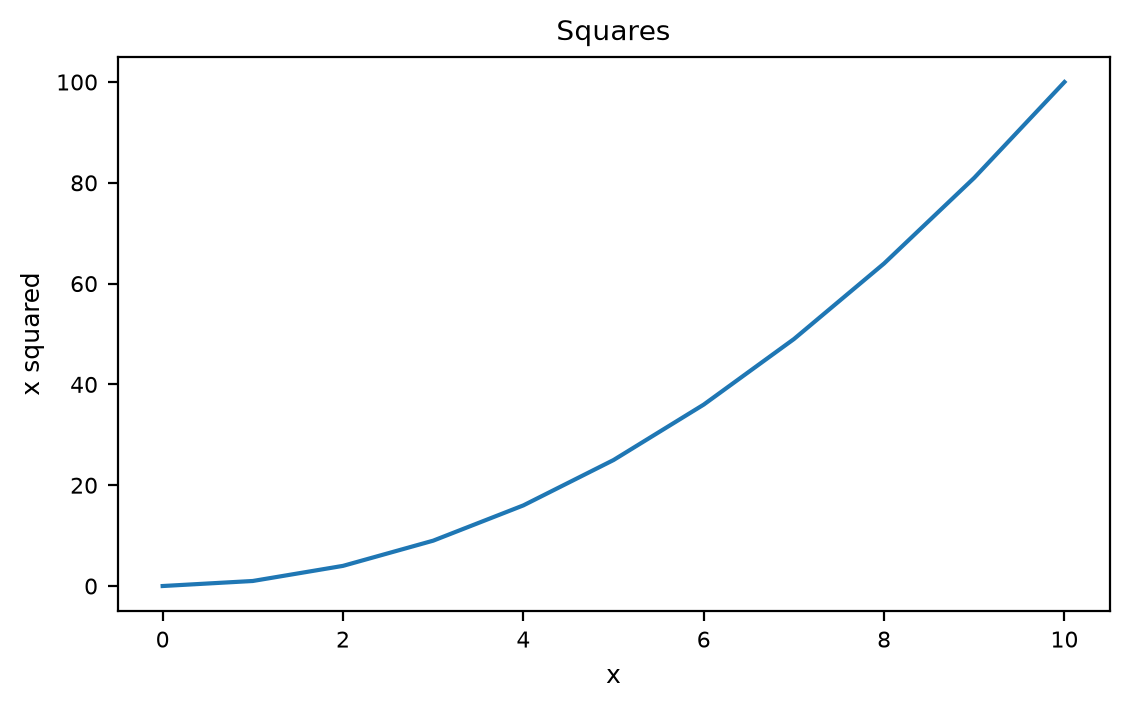

In [775]:
x = np.arange(0, 11)
y = x ** 2
plt.plot(x, y)
plt.title("Squares")
plt.xlabel("x")
plt.ylabel("x squared");

With `ax.`, the figure and axes are created first, then methods are called on `ax`. Note that titles and labels become `set_...`:

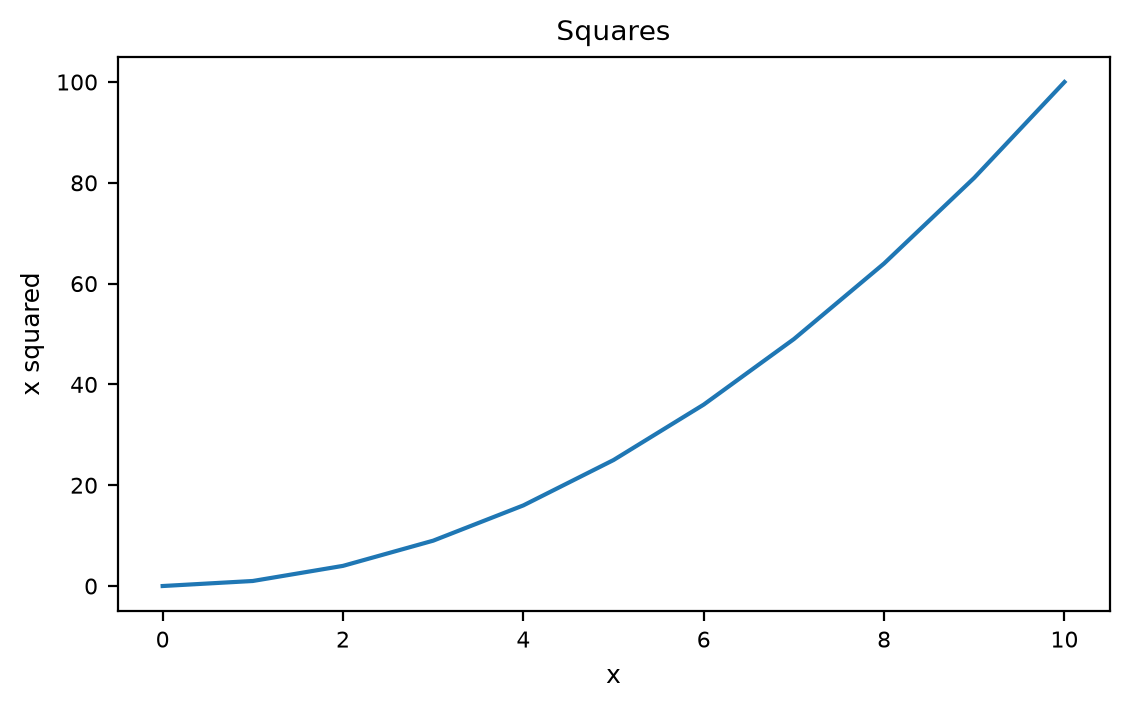

In [776]:
x = np.arange(0, 11)
y = x ** 2
fig, ax = plt.subplots()
ax.plot(x, y)
ax.set_title("Squares")
ax.set_xlabel("x")
ax.set_ylabel("x squared");

`ax.set(...)` sets several properties in one call:

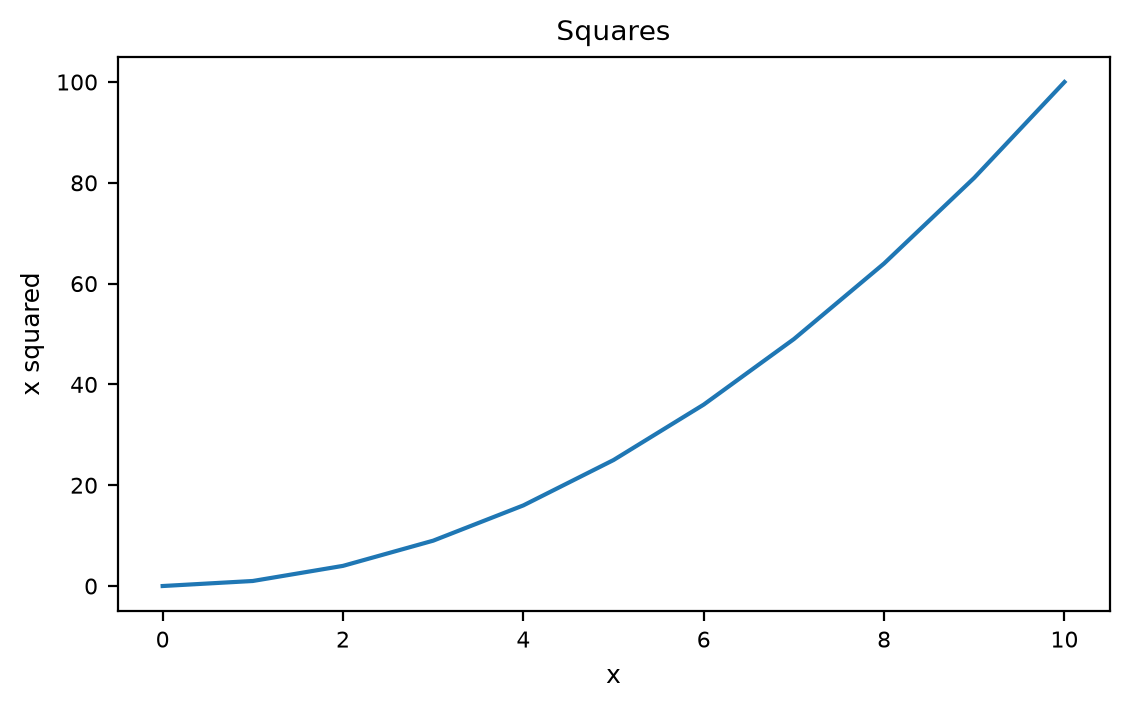

In [777]:
fig, ax = plt.subplots()
ax.plot(x, y)
ax.set(title="Squares", xlabel="x", ylabel="x squared");

| `plt.` command | `ax.` equivalent |
|---|---|
| `plt.plot(x, y)` | `ax.plot(x, y)` |
| `plt.title("t")` | `ax.set_title("t")` |
| `plt.xlabel("x")`, `plt.ylabel("y")` | `ax.set_xlabel("x")`, `ax.set_ylabel("y")` |
| `plt.xlim(0, 10)`, `plt.ylim(0, 5)` | `ax.set_xlim(0, 10)`, `ax.set_ylim(0, 5)` |
| `plt.xticks(v)` | `ax.set_xticks(v)` |
| `plt.xscale("log")` | `ax.set_xscale("log")` |
| `plt.legend()`, `plt.grid()` | `ax.legend()`, `ax.grid()` |
| `plt.tight_layout()` | `fig.tight_layout()` |
| `plt.subplot(1, 2, 1)` | `fig, axs = plt.subplots(1, 2)` then `axs[0]` |

*See also:* Drawing a simple line plot (C1) · Adding a title and axis labels (C1) · Drawing panels with `plt.subplots` (C2)

### Line plots and styles

#### Drawing a simple line plot

**C1.02**

`plt.plot(x, y)`

The `plt.plot(x, y)` function allows us to draw a line through a set of points. It is useful for showing how one quantity changes with another. Alternatively, `sns.lineplot` or `df.plot()` draw from a DataFrame.

Give `plt.plot` a list or array of x values and one of y values of the same length. The data are displayed first.

In [778]:
x = np.arange(0, 11)       # 0, 1, ..., 10
y = x ** 2
x

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [779]:
# display example data
y

array([  0,   1,   4,   9,  16,  25,  36,  49,  64,  81, 100])

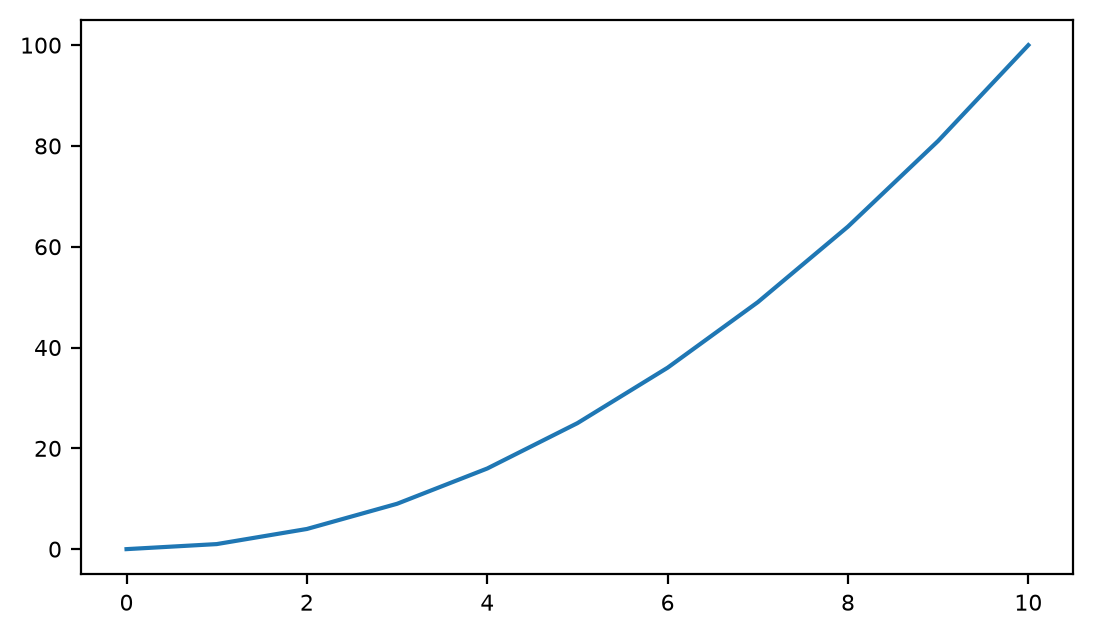

In [780]:
plt.plot(x, y);

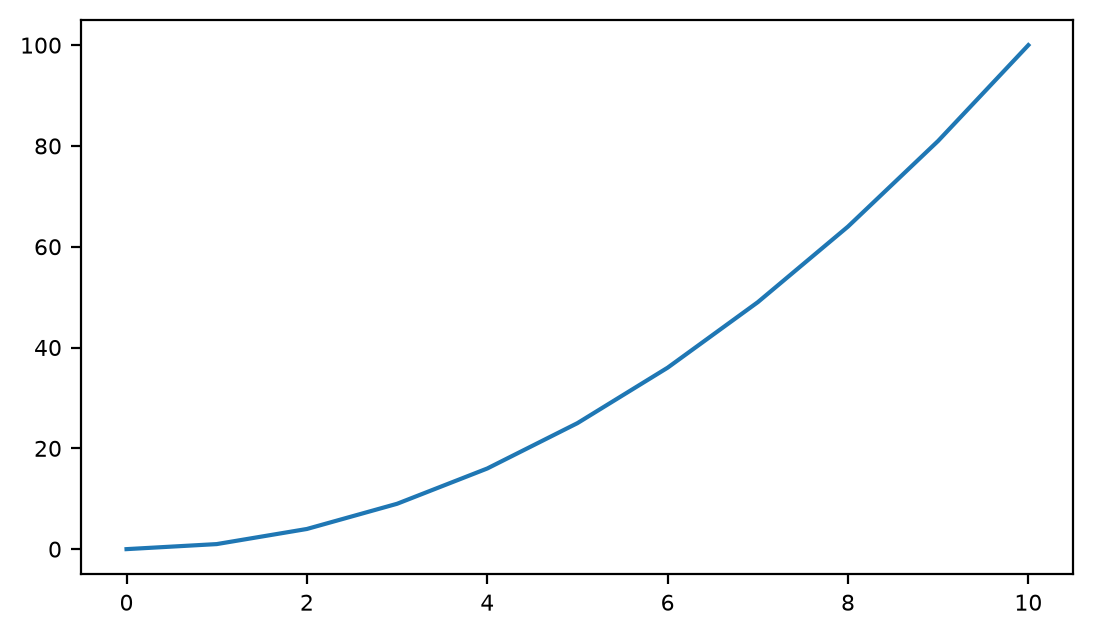

In [781]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(x, y);

*See also:* Styling a line with a format string (C1) · Adding a title and axis labels (C1) · Collecting results in a list with `append` (A2)

#### Plotting markers only

**C1.03**

`plt.plot(x, y, 'x')  'o'  '^'  '.'  's'`

A format string such as `'o'` or `'s'` allows us to draw individual points instead of a connected line. It is useful for measurements, where joining the dots would suggest values in between. Alternatively, `plt.scatter` draws points with more options.

Common markers: `o` circle, `s` square, `^` triangle, `x` cross, `.` dot. By default `plt.plot` joins the points with a line:

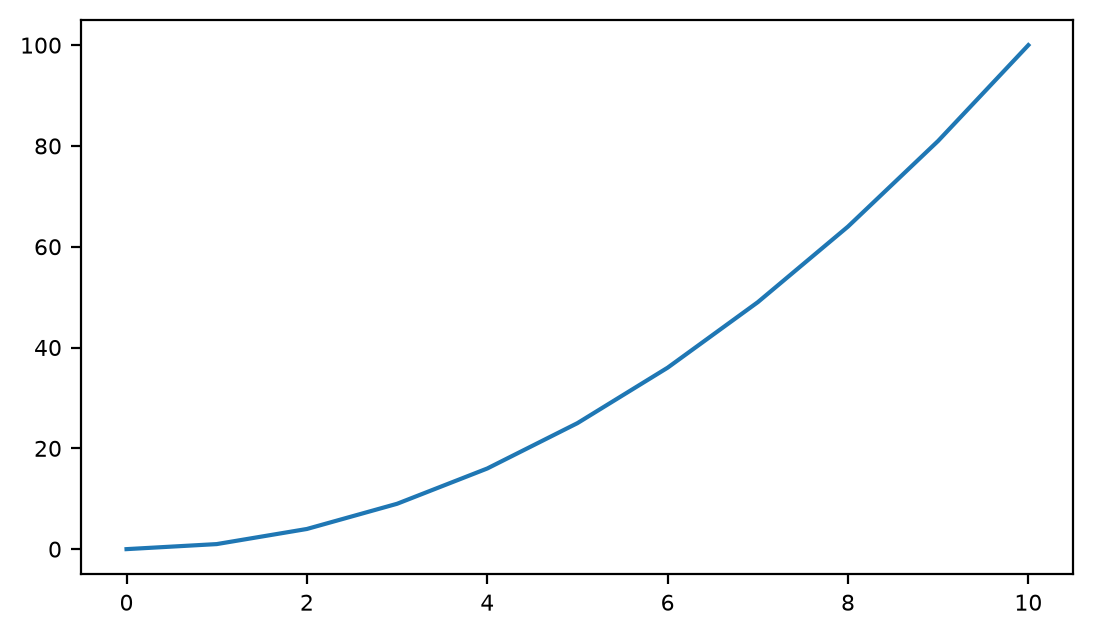

In [782]:
x = np.arange(0, 11)
y = x ** 2
plt.plot(x, y);

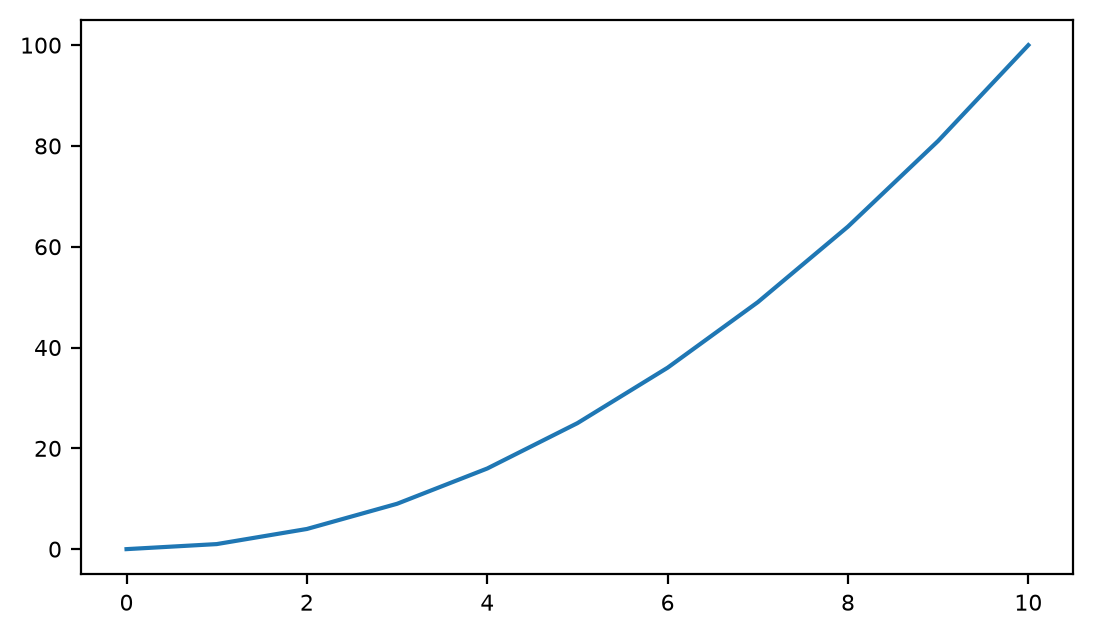

In [783]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
y = x ** 2
fig, ax = plt.subplots()
ax.plot(x, y);

A marker code as the third argument draws the points only:

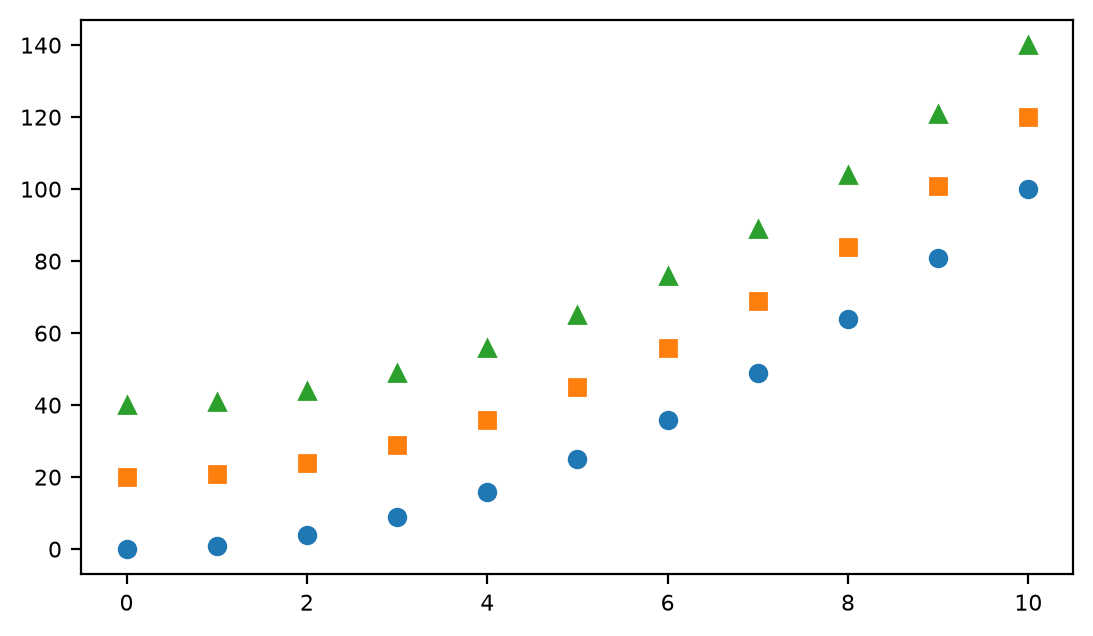

In [784]:
plt.plot(x, y, "o")           # circles
plt.plot(x, y + 20, "s")      # squares
plt.plot(x, y + 40, "^");      # triangles

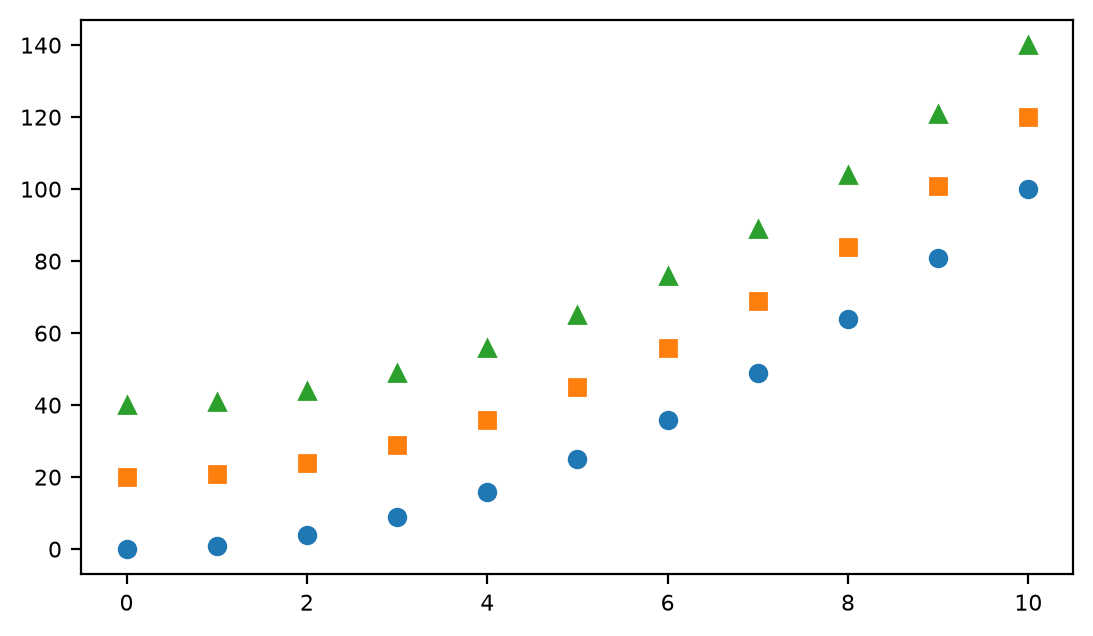

In [785]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(x, y, "o")           # circles
ax.plot(x, y + 20, "s")      # squares
ax.plot(x, y + 40, "^");      # triangles

*See also:* Styling a line with a format string (C1) · Drawing a scatter plot (C2) · Drawing a simple line plot (C1)

#### Styling a line with a format string

**C1.04**

`'bx-'  'r+-'  'go-'  'm.--'  'k^:'`

A format string combining a colour letter, a marker and a line style allows us to style a line in three characters, such as `'bx-'`. It is useful for quick, compact styling. Alternatively, keyword arguments (`color=`, `marker=`, `linestyle=`) name each choice and allow more options.

Colours: `b g r c m y k`. Lines: `-` solid, `--` dashed, `:` dotted.

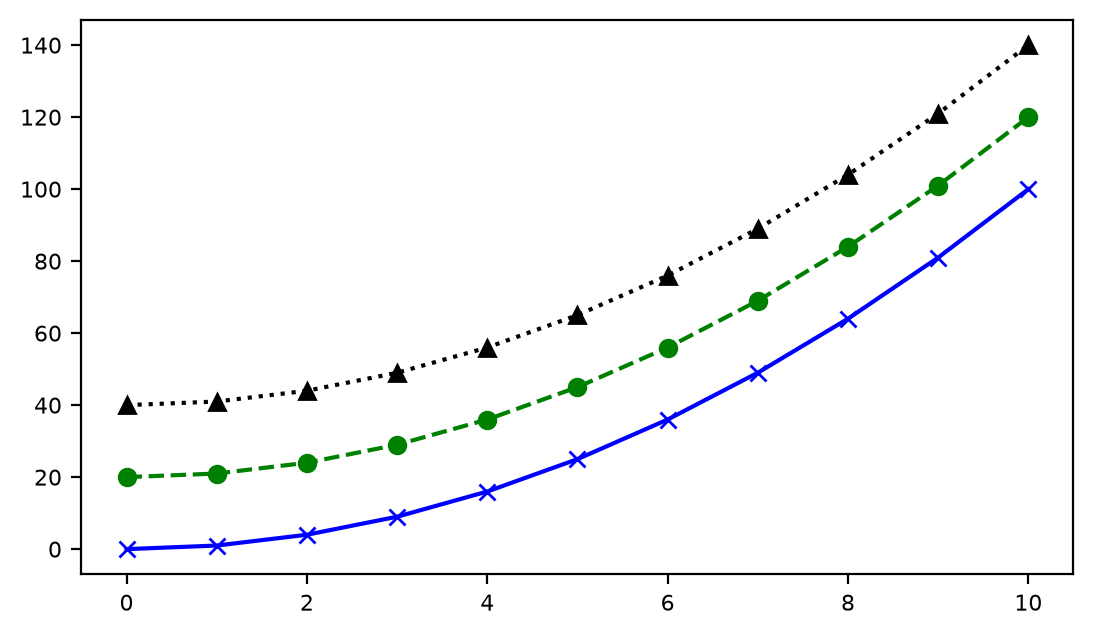

In [786]:
x = np.arange(0, 11)
y = x ** 2
plt.plot(x, y, "bx-")         # blue, crosses, solid
plt.plot(x, y + 20, "go--")   # green, circles, dashed
plt.plot(x, y + 40, "k^:");    # black, triangles, dotted

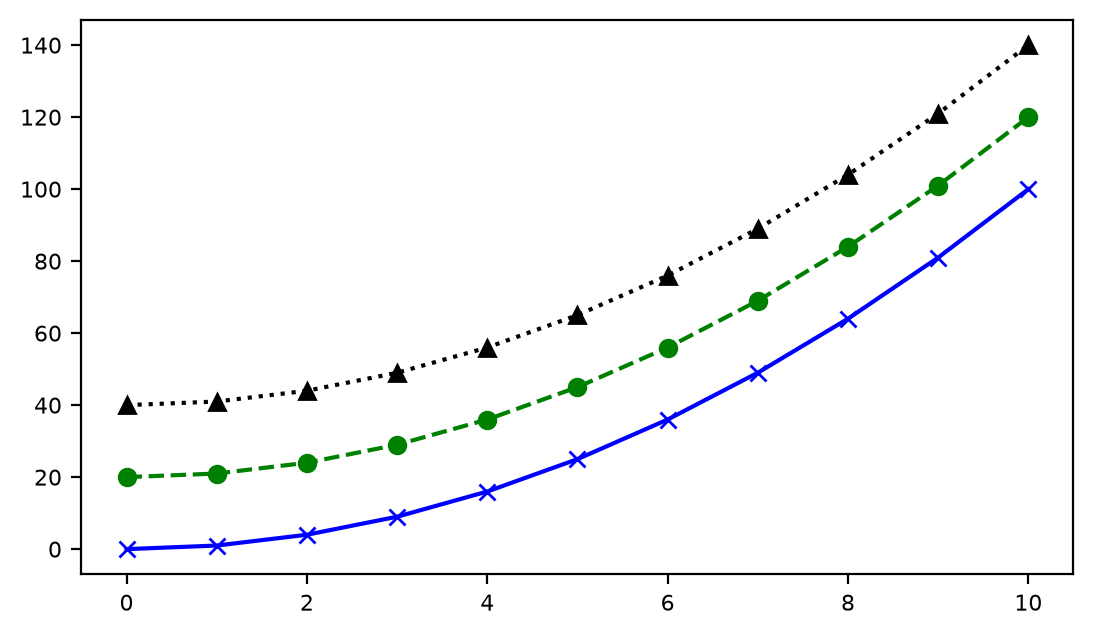

In [787]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
y = x ** 2
fig, ax = plt.subplots()
ax.plot(x, y, "bx-")         # blue, crosses, solid
ax.plot(x, y + 20, "go--")   # green, circles, dashed
ax.plot(x, y + 40, "k^:");    # black, triangles, dotted

*See also:* Styling a line with keyword arguments (C1) · Plotting markers only (C1) · Drawing a simple line plot (C1)

#### Styling a line with keyword arguments

**C1.05**

`color=c, linestyle=style, linewidth=w, markersize=m, alpha=a`

Keyword arguments such as `color=`, `linestyle=`, `linewidth=` and `markersize=` allow us to style a line by name. They are useful when full control and readable code are needed. Alternatively, a format string is quicker for simple styles.

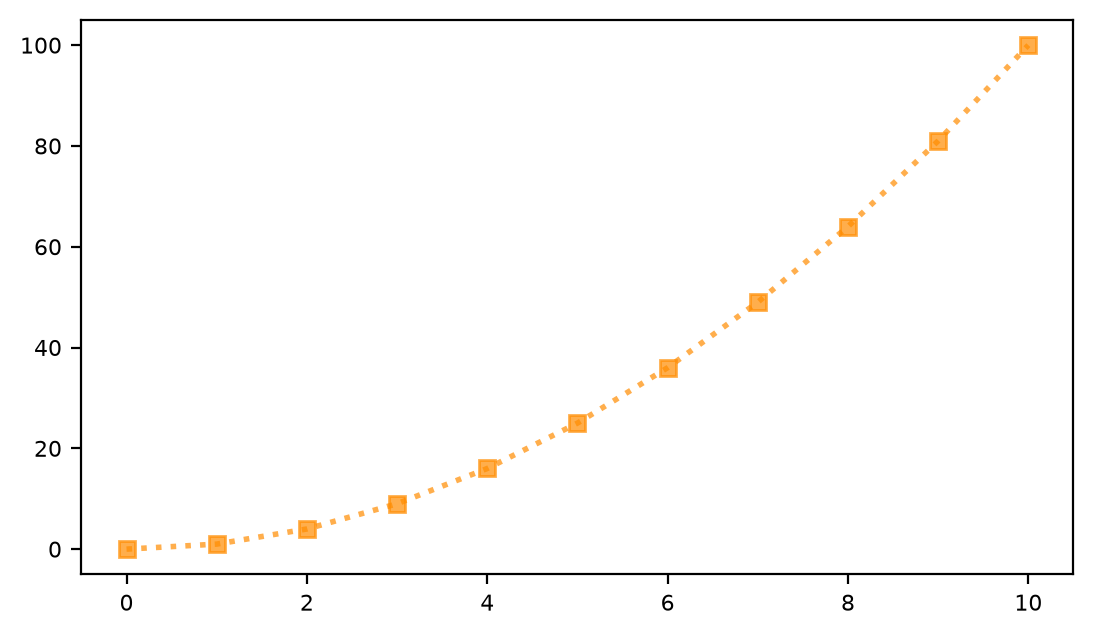

In [788]:
x = np.arange(0, 11)
y = x ** 2
plt.plot(x, y, color="darkorange", linestyle="dotted", marker="s",
         linewidth=2, markersize=6, alpha=0.7);

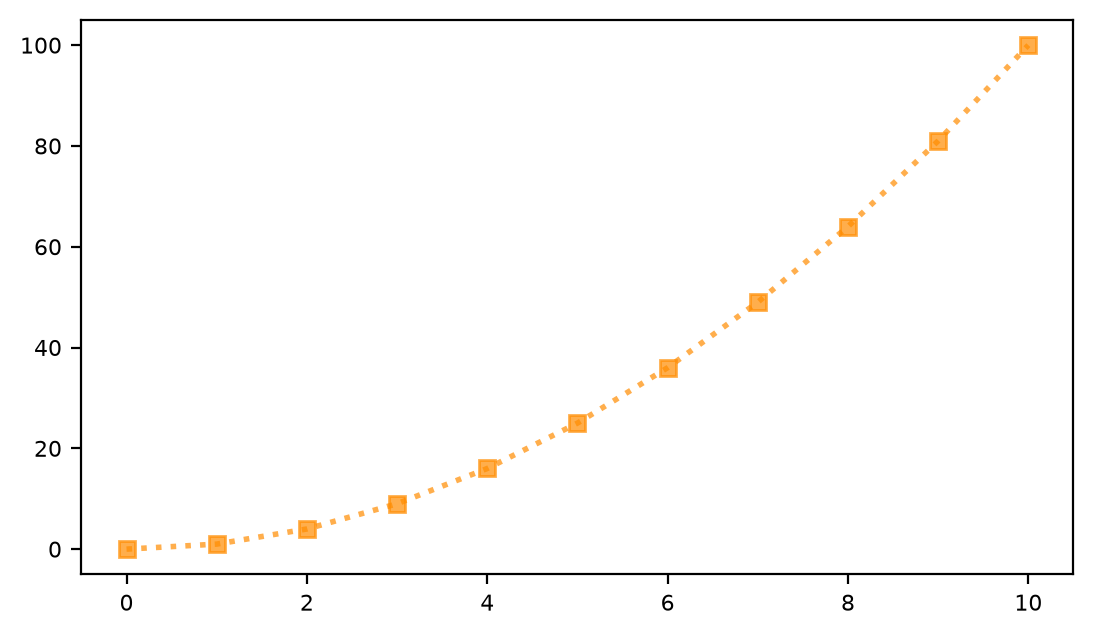

In [789]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
y = x ** 2
fig, ax = plt.subplots()
ax.plot(x, y, color="darkorange", linestyle="dotted", marker="s",
         linewidth=2, markersize=6, alpha=0.7);

*See also:* Styling a line with a format string (C1) · Making points or lines transparent (C1)

#### Adding a legend for several lines

**C1.06**

`plt.plot(..., label=text); plt.legend()`

The `label=` argument with `plt.legend()` allows us to name each line and show a key. It is useful whenever a plot has more than one line. Alternatively, in seaborn `hue=` creates the legend automatically.

Two lines are plotted; without labels there is no way to tell which is which.

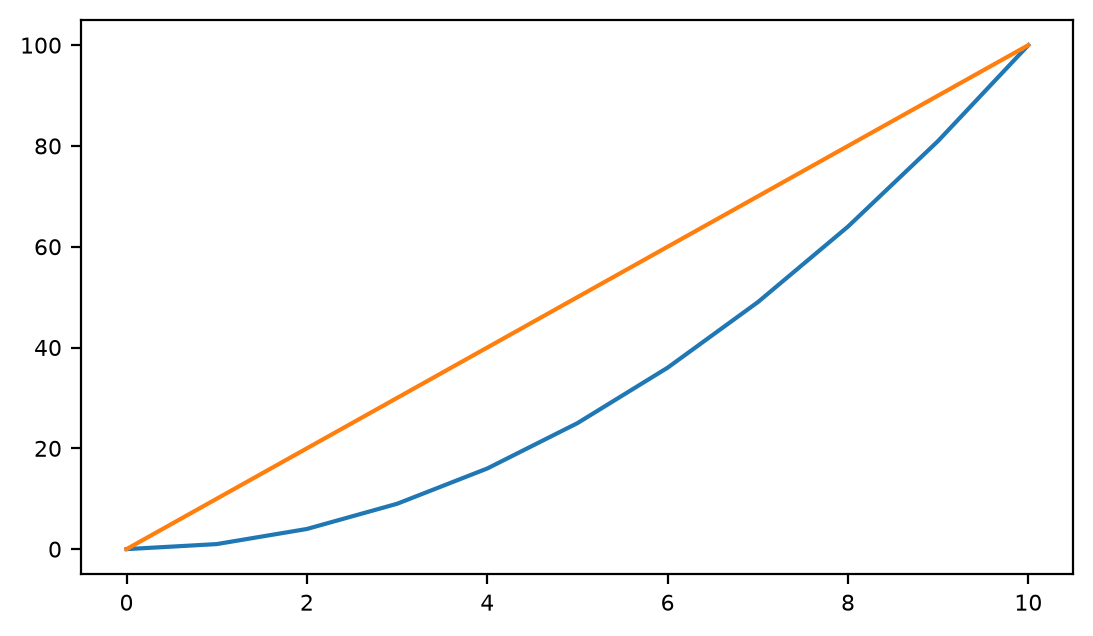

In [790]:
x = np.arange(0, 11)
plt.plot(x, x ** 2)
plt.plot(x, x * 10);

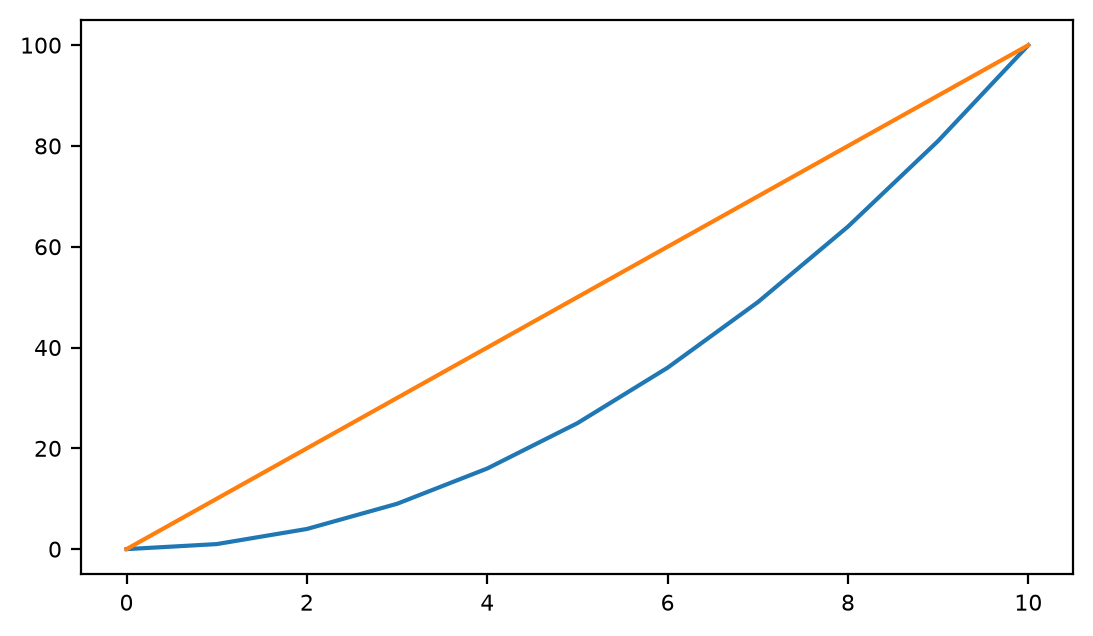

In [791]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2)
ax.plot(x, x * 10);

`label=` names each line and `plt.legend()` draws the key:

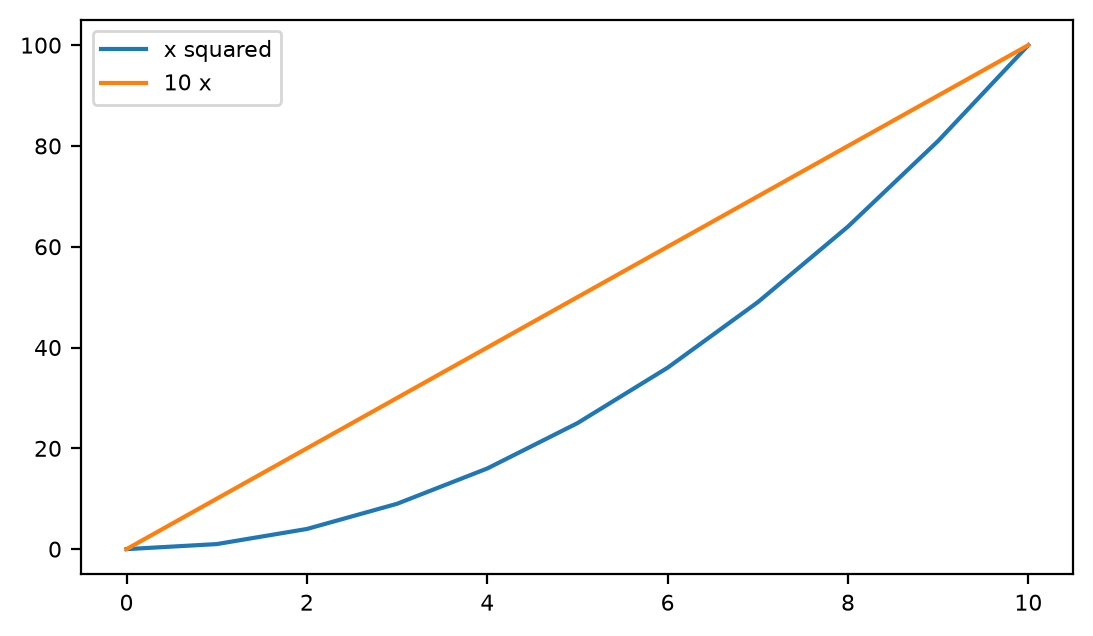

In [792]:
plt.plot(x, x ** 2, label="x squared")
plt.plot(x, x * 10, label="10 x")
plt.legend();

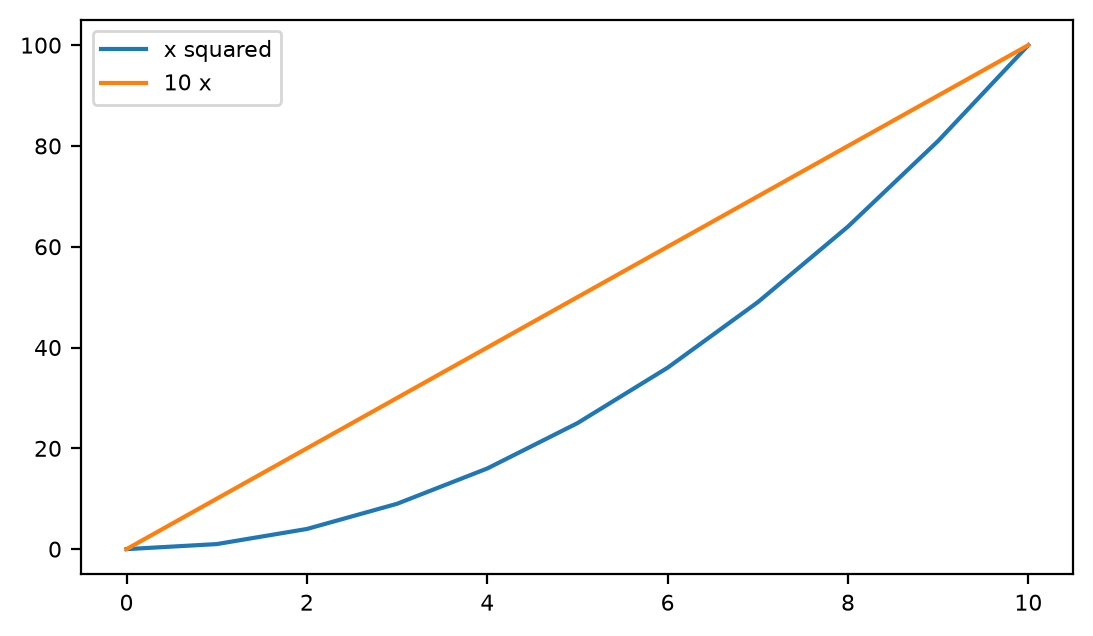

In [793]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(x, x ** 2, label="x squared")
ax.plot(x, x * 10, label="10 x")
ax.legend();

*See also:* Moving the legend (C1) · Overlaying lines on one axis (C3)

#### Moving the legend

**C1.07**

`plt.legend(loc='upper left')`

***(non-examinable)***

The `loc=` argument of `plt.legend()` allows us to place the key where it does not cover the data. It is useful for crowded plots. Alternatively, `loc="best"` lets matplotlib choose.

By default matplotlib chooses a position (`loc="best"`):

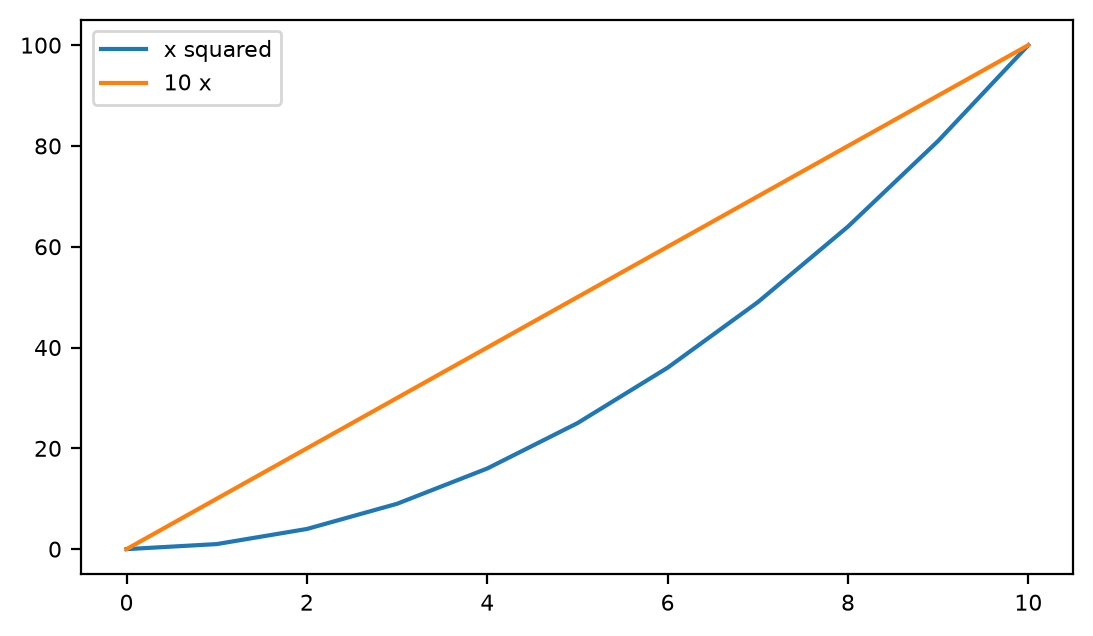

In [794]:
x = np.arange(0, 11)
plt.plot(x, x ** 2, label="x squared")
plt.plot(x, x * 10, label="10 x")
plt.legend();

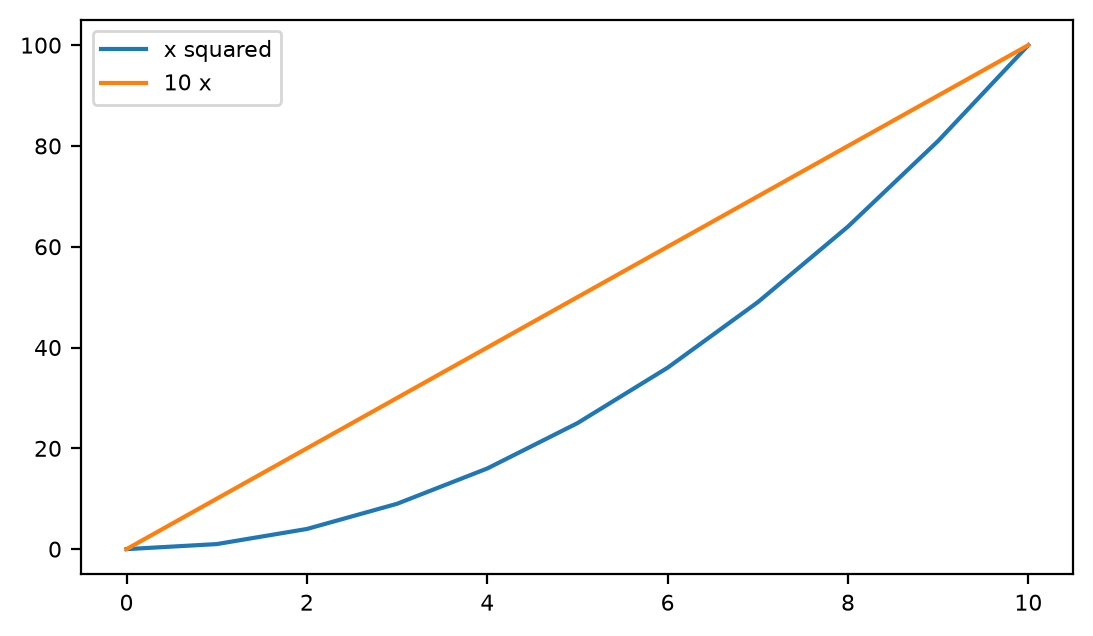

In [795]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2, label="x squared")
ax.plot(x, x * 10, label="10 x")
ax.legend();

`loc=` places the key at a chosen position (for example `'lower right'` or `'center'`):

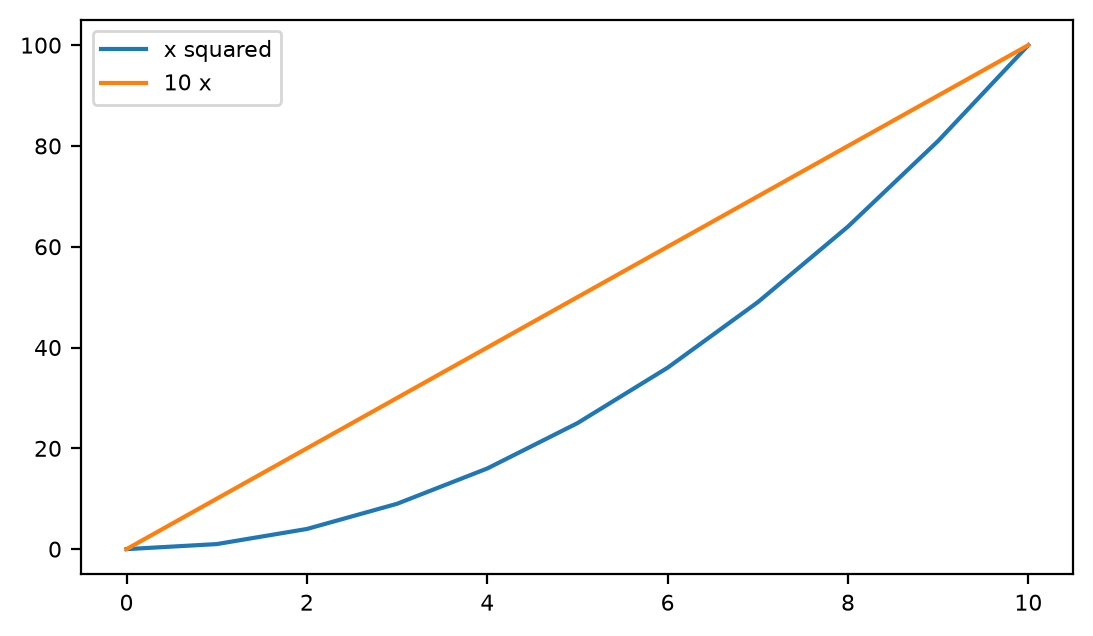

In [796]:
plt.plot(x, x ** 2, label="x squared")
plt.plot(x, x * 10, label="10 x")
plt.legend(loc="upper left");

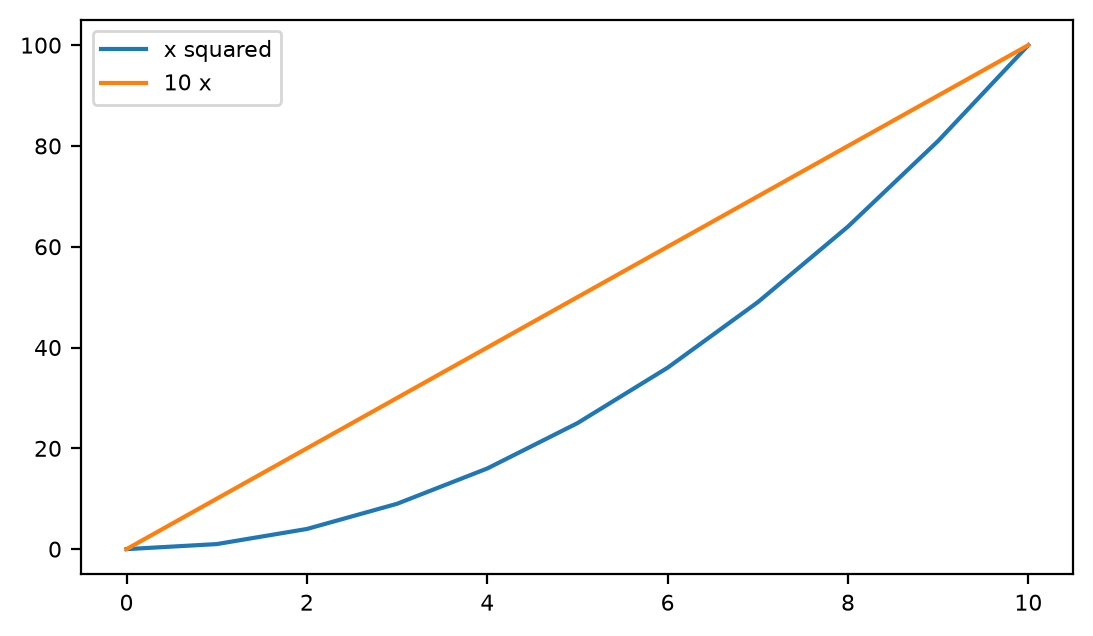

In [797]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(x, x ** 2, label="x squared")
ax.plot(x, x * 10, label="10 x")
ax.legend(loc="upper left");

*See also:* Adding a legend for several lines (C1) · Drawing a simple line plot (C1) · Choosing between `plt` and `ax` (C1)

### Titles and labels

#### Adding a title and axis labels

**C1.08**

`plt.title(), plt.xlabel(), plt.ylabel()`

The functions `plt.title()`, `plt.xlabel()` and `plt.ylabel()` allow us to say what a plot shows and what the axes mean. They are useful for *every* plot that is presented, with units where relevant. Alternatively, `ax.set(title=..., xlabel=..., ylabel=...)` sets all three at once.

Without labels the plot does not say what it shows:

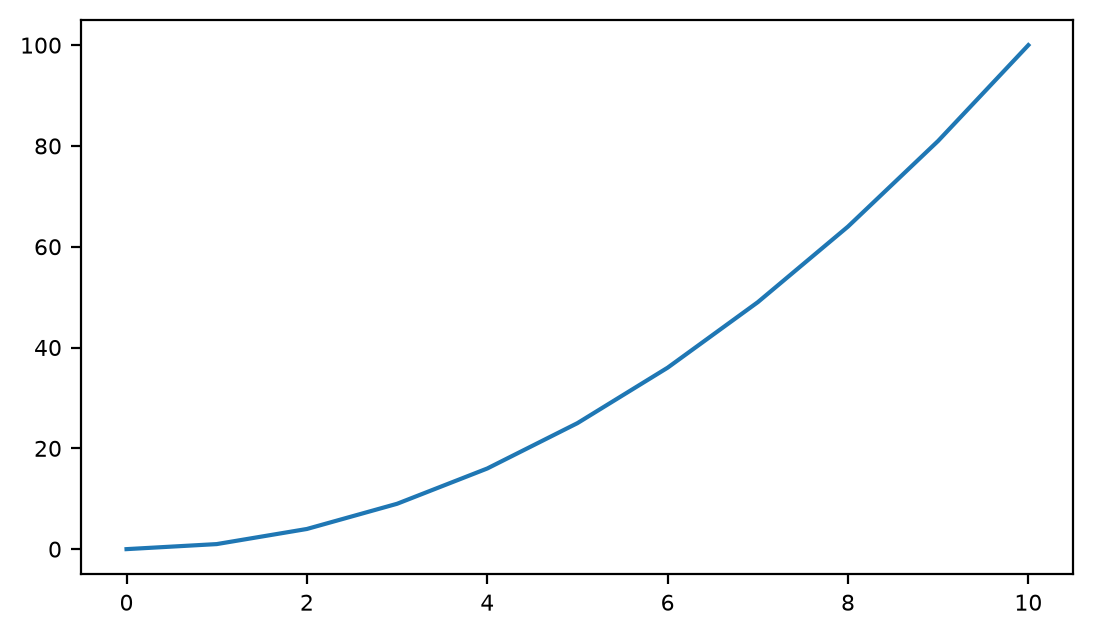

In [798]:
x = np.arange(0, 11)
plt.plot(x, x ** 2);

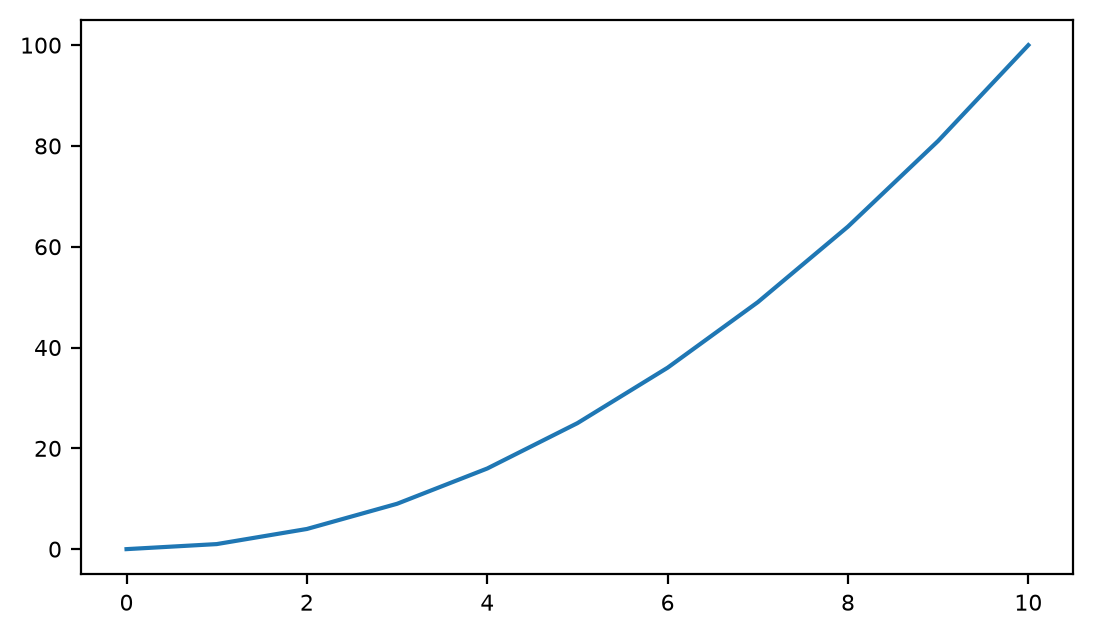

In [799]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2);

A title and axis labels (with units where relevant) are added with three functions:

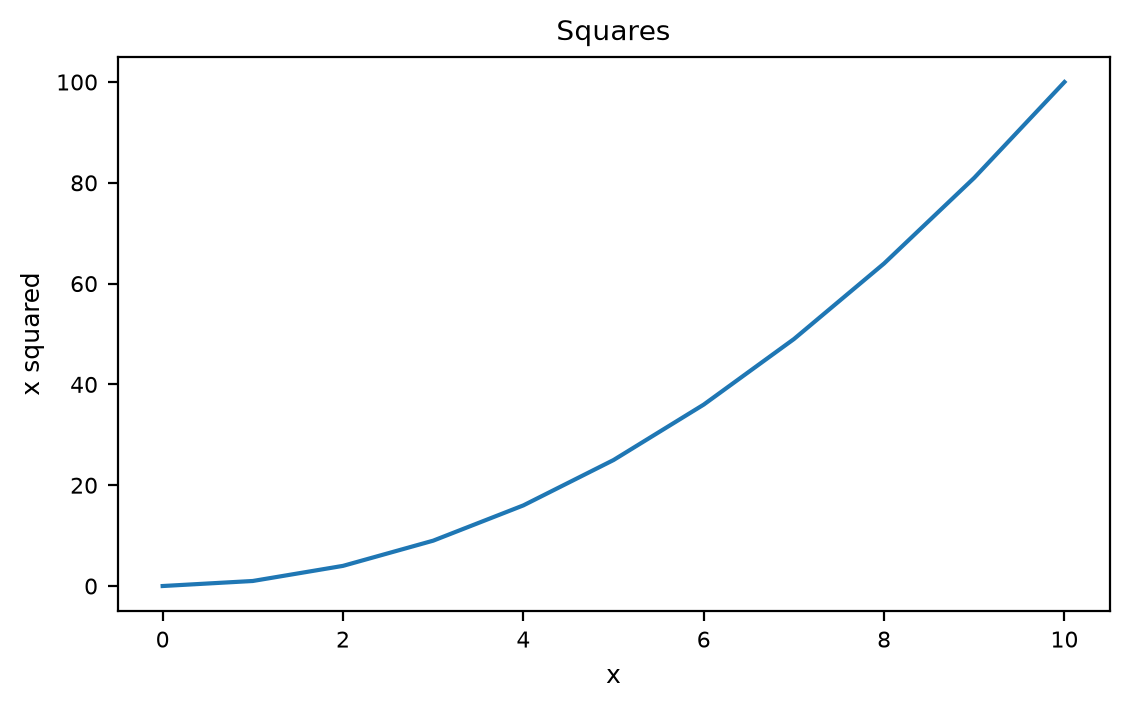

In [800]:
plt.plot(x, x ** 2)
plt.title("Squares")
plt.xlabel("x")
plt.ylabel("x squared");

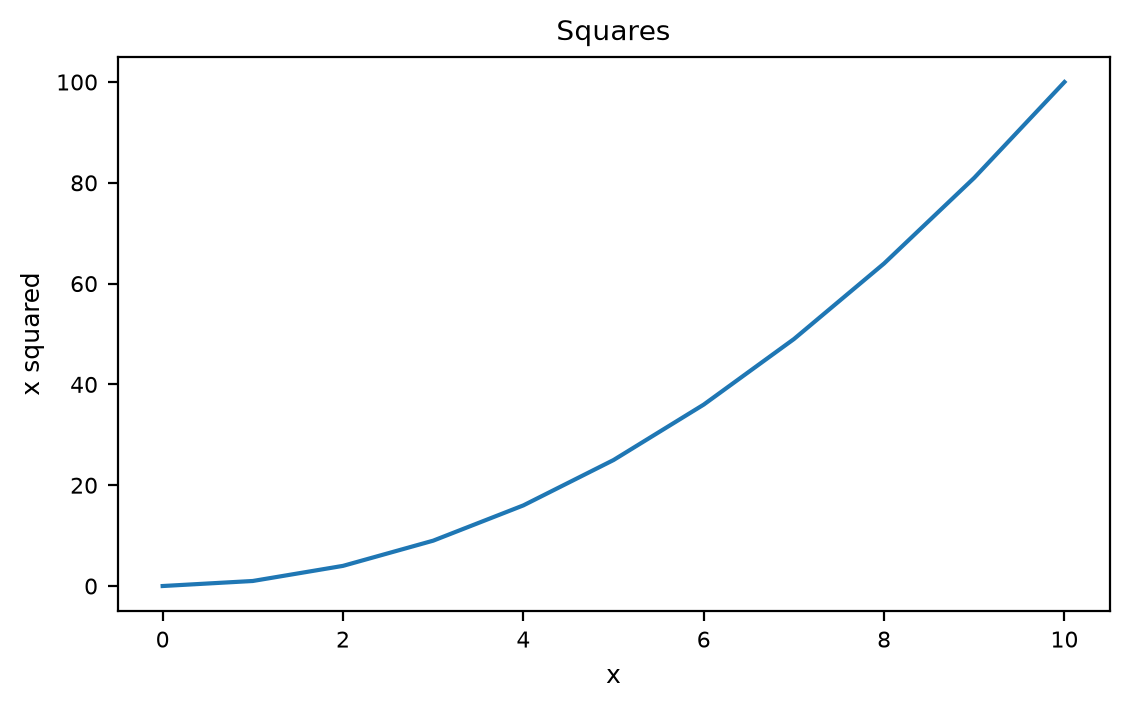

In [801]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(x, x ** 2)
ax.set_title("Squares")
ax.set_xlabel("x")
ax.set_ylabel("x squared");

*See also:* Drawing panels with `plt.subplots` (C2) · Drawing a simple line plot (C1) · Labelling axes with names and units (C4)

#### Annotating with text

**C1.09**

`plt.text(x, y, "text")`

The `plt.text(x, y, "text")` function allows us to write a label at a chosen position in data coordinates. It is useful for equations, a note on an outlier or a value. Alternatively, `plt.annotate` can add an arrow.

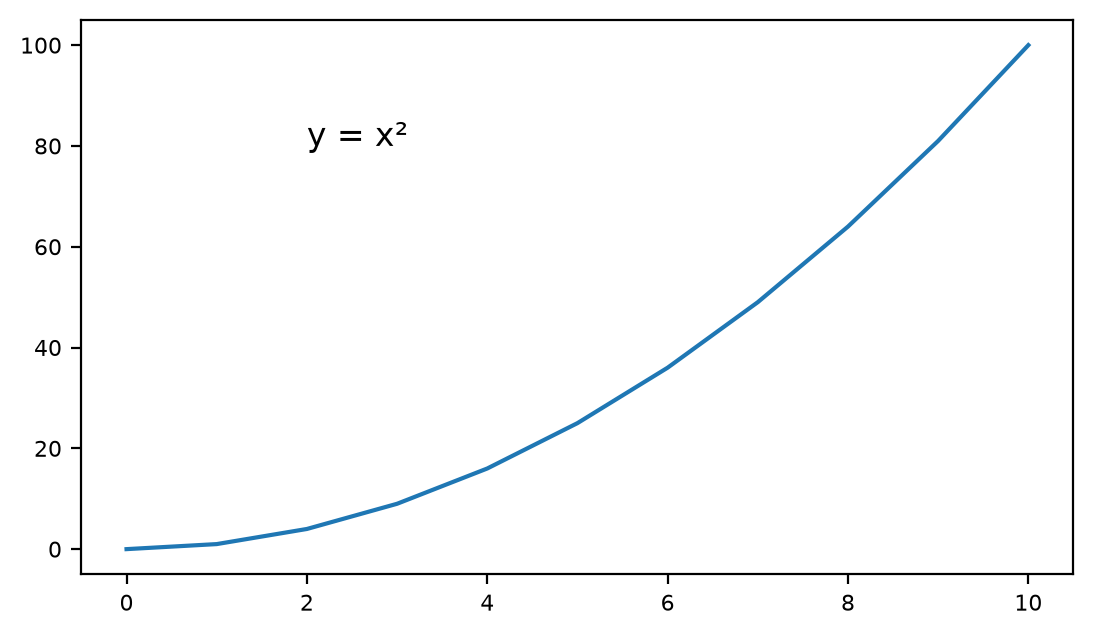

In [802]:
x = np.arange(0, 11)
plt.plot(x, x ** 2)
plt.text(2, 80, "y = x²", fontsize=12);      # x = 2, y = 80 on the axes

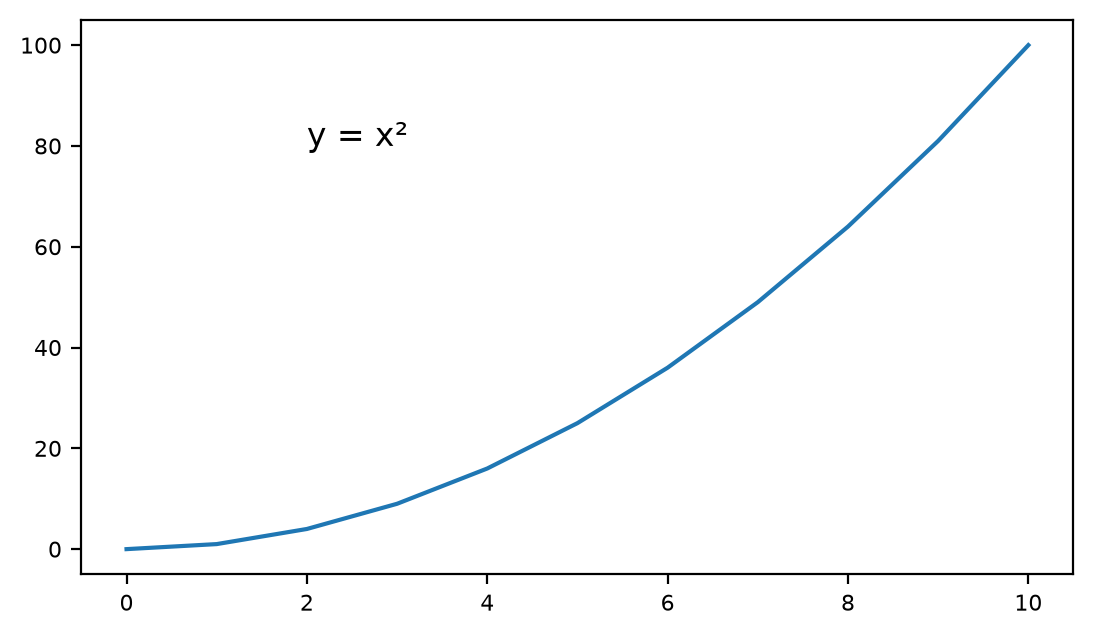

In [803]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2)
ax.text(2, 80, "y = x²", fontsize=12);      # x = 2, y = 80 on the axes

*See also:* Writing the equation on the plot (D5) · Marking a date on a plot (B8) · Setting axis limits (C1)

### Axes

#### Setting axis limits

**C1.10**

`plt.xlim(low, high), plt.ylim(low, high)`

The `plt.xlim()` and `plt.ylim()` functions allow us to choose the range shown on each axis. They are useful for zooming in or making several plots comparable. Alternatively, `ax.set_xlim()` does the same on an axes object.

By default the axes cover the full range of the data:

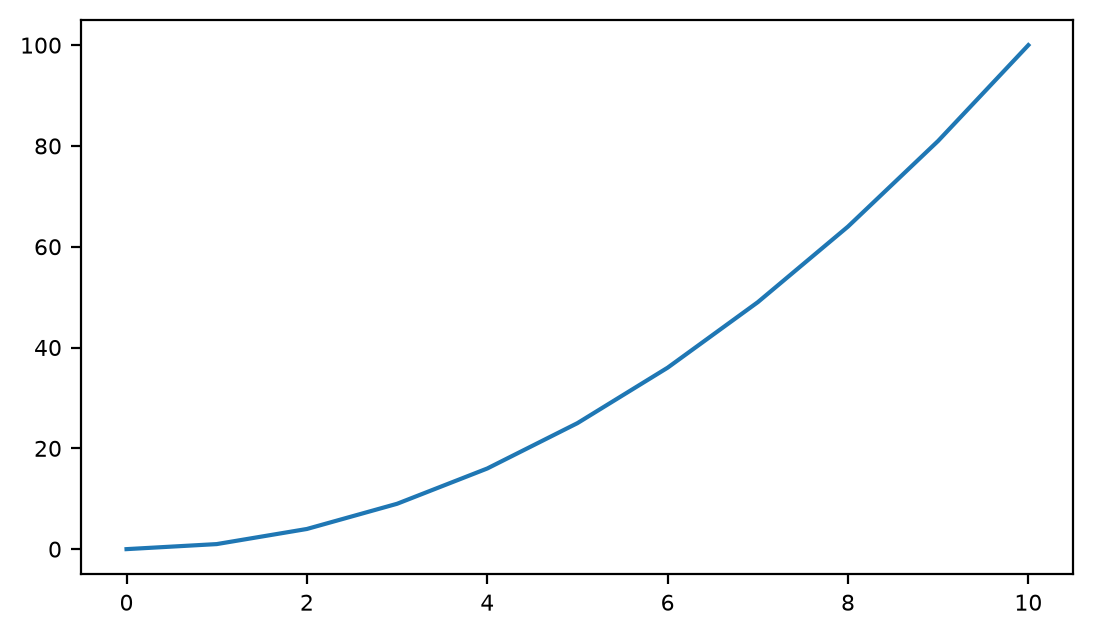

In [804]:
x = np.arange(0, 11)
plt.plot(x, x ** 2);

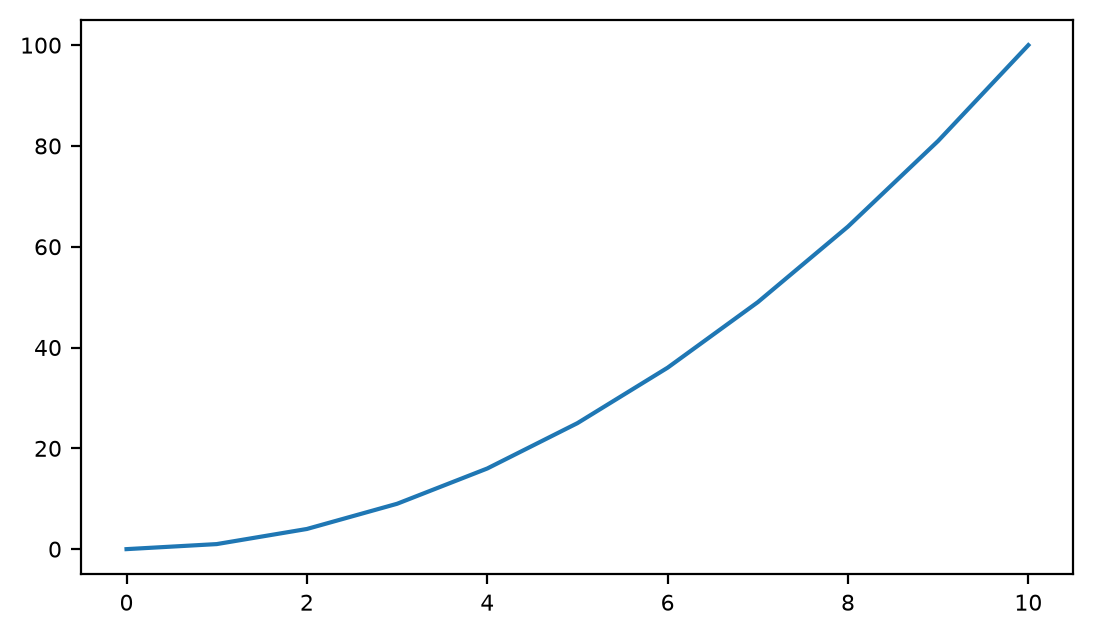

In [805]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2);

`plt.xlim` and `plt.ylim` zoom in on a chosen range:

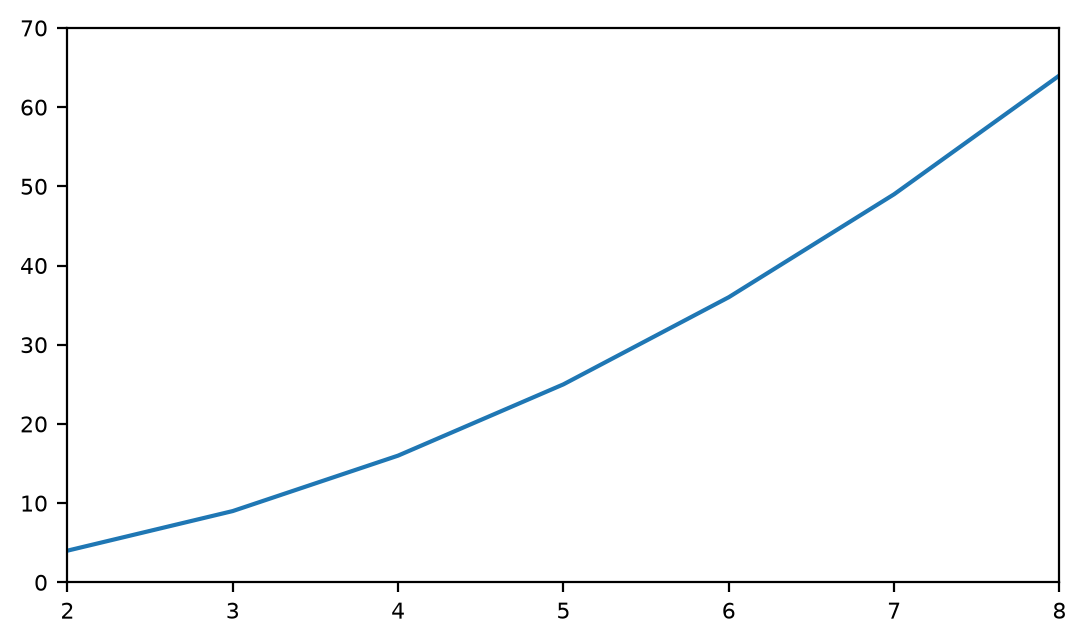

In [806]:
plt.plot(x, x ** 2)
plt.xlim(2, 8)
plt.ylim(0, 70);

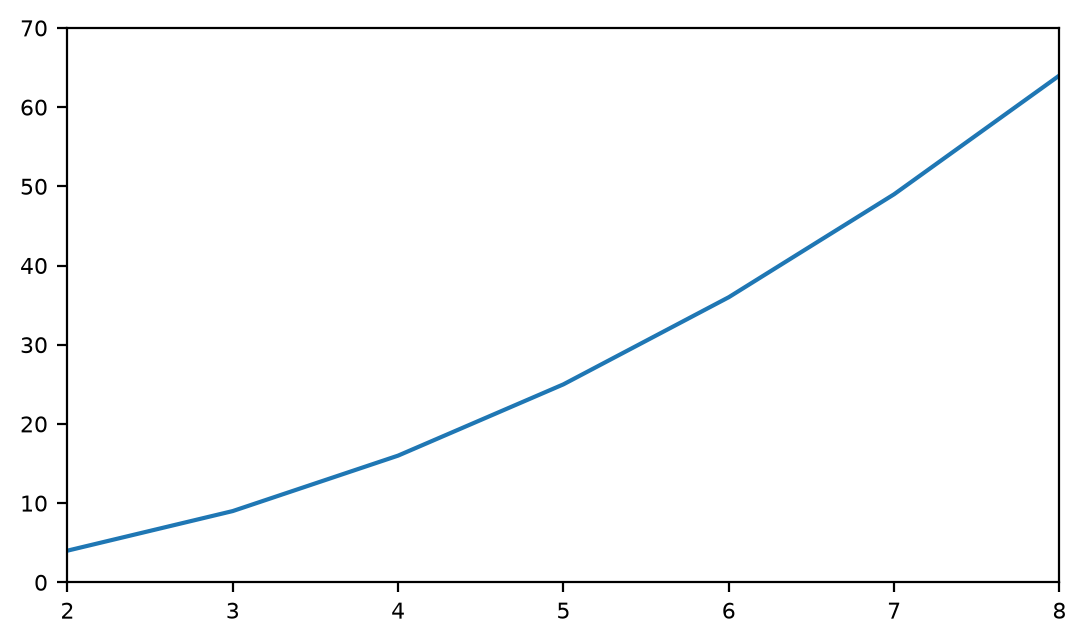

In [807]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(x, x ** 2)
ax.set_xlim(2, 8)
ax.set_ylim(0, 70);

*See also:* Setting tick positions (C1) · Using a log scale (C1) · Adding a grid (C1)

#### Setting tick positions

**C1.11**

`plt.xticks(positions)`

The `plt.xticks()` and `plt.yticks()` functions allow us to choose exactly where tick marks and labels appear. They are useful for neat, regular scales. Alternatively, `plt.locator_params(nbins=…)` sets how many ticks there are.

The default tick positions are chosen automatically:

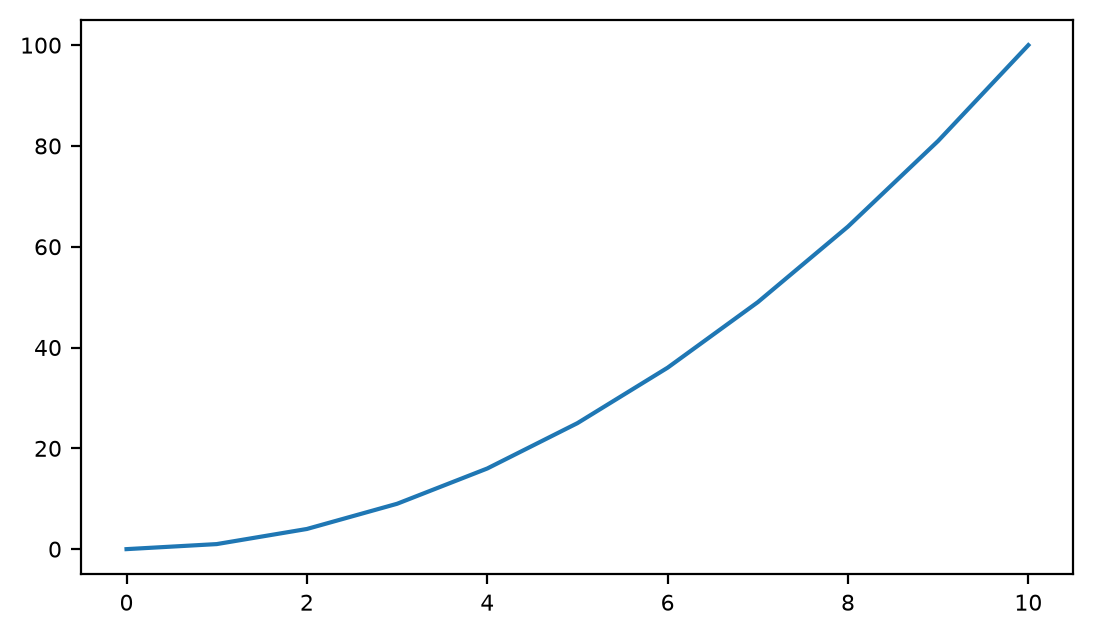

In [808]:
x = np.arange(0, 11)
plt.plot(x, x ** 2);

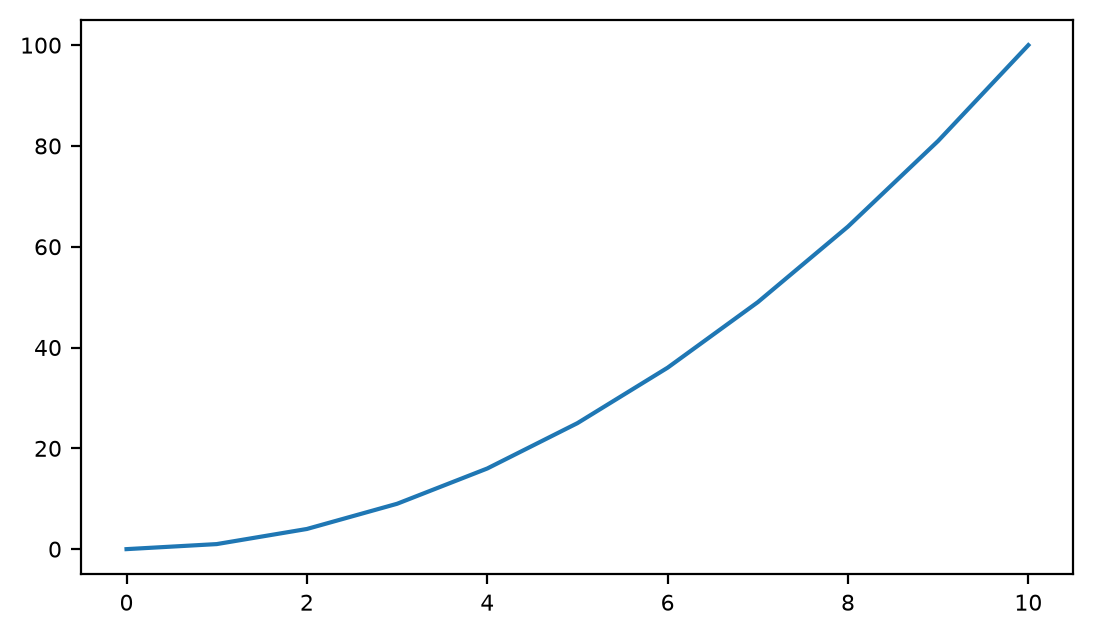

In [809]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2);

`plt.xticks` and `plt.yticks` set the positions explicitly:

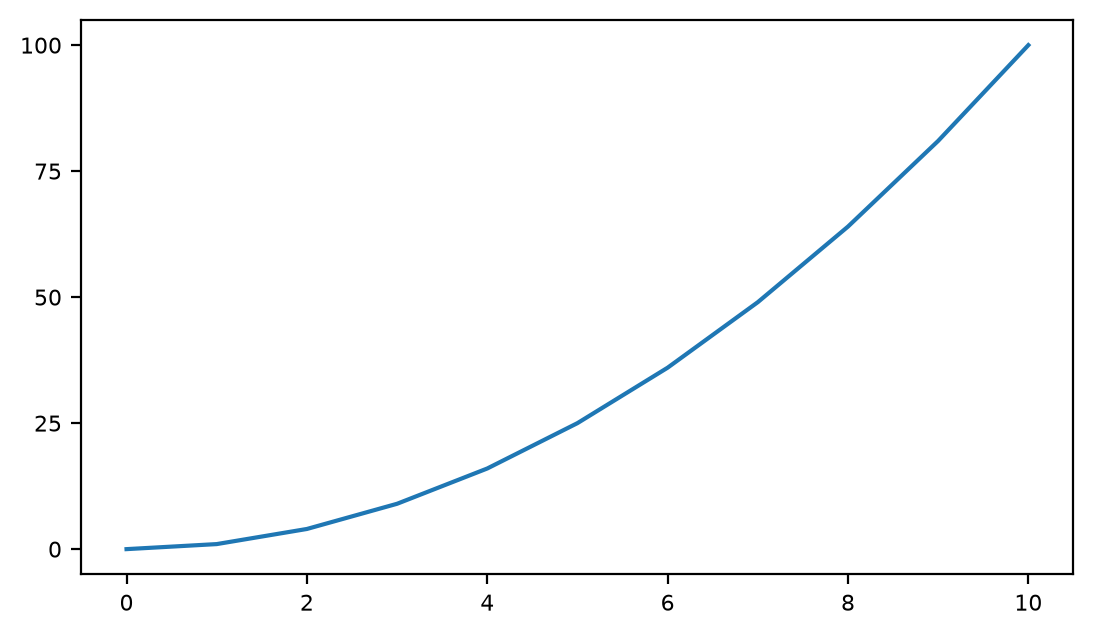

In [810]:
plt.plot(x, x ** 2)
plt.xticks(np.arange(0, 10.1, 2))
plt.yticks(np.arange(0, 101, 25));

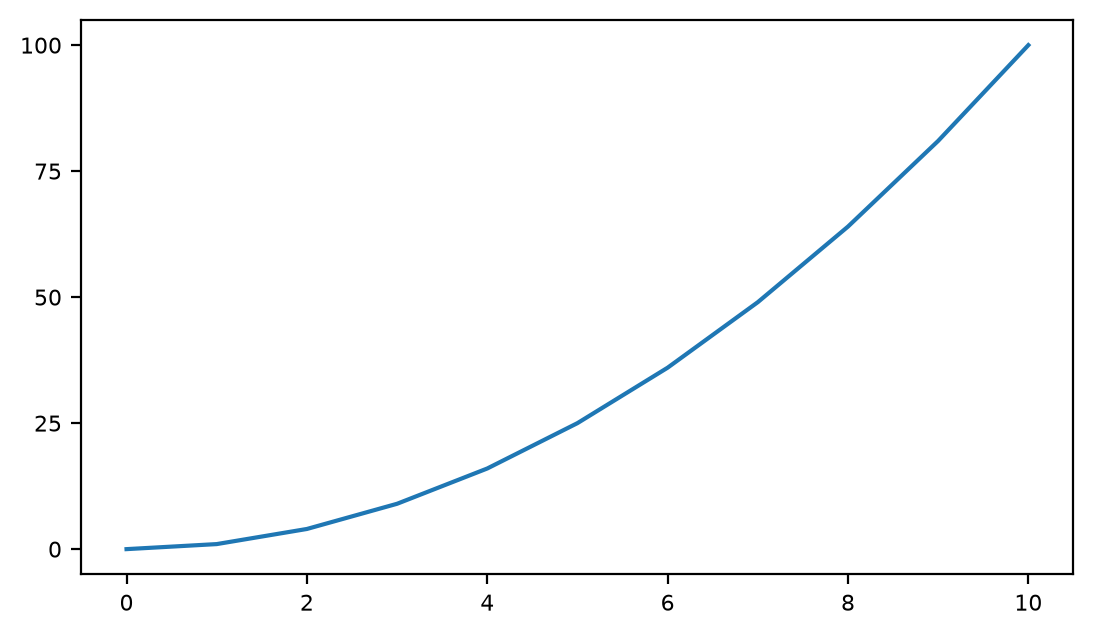

In [811]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(x, x ** 2)
ax.set_xticks(np.arange(0, 10.1, 2))
ax.set_yticks(np.arange(0, 101, 25));

*See also:* Setting axis limits (C1) · Creating a sequence with `np.arange` (A4) · Rotating the date labels (B8)

#### Adding a grid

**C1.12**

`plt.grid()`

The `plt.grid()` function allows us to draw light grid lines behind the data. It is useful for reading values off a plot. Alternatively, `sns.set_theme(style="whitegrid")` adds grid lines to every plot.

The default plot has no grid lines:

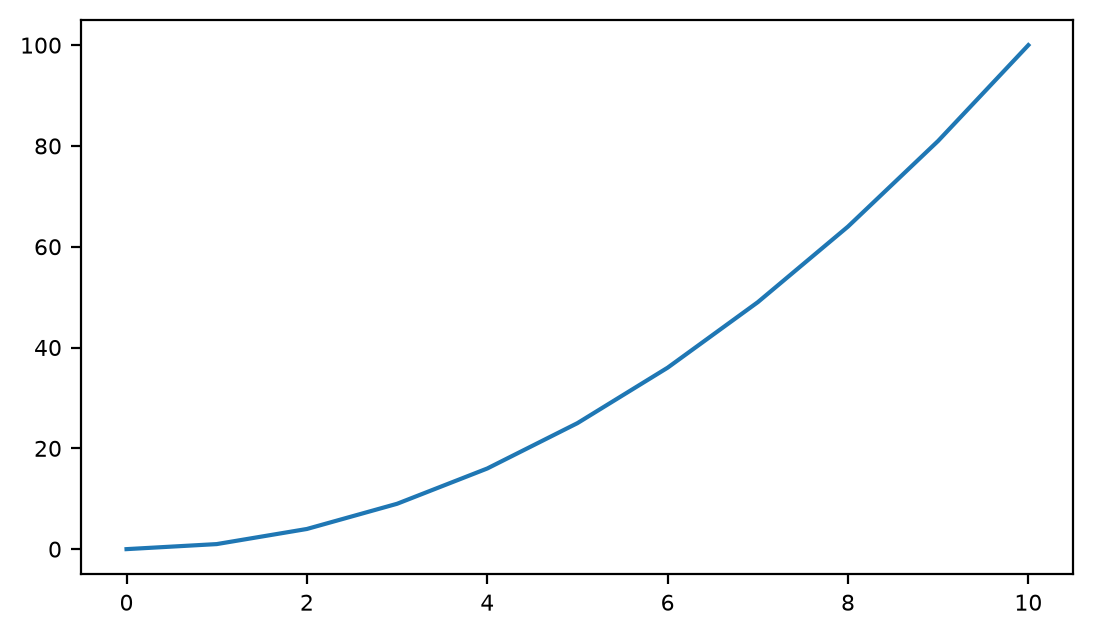

In [812]:
x = np.arange(0, 11)
plt.plot(x, x ** 2);

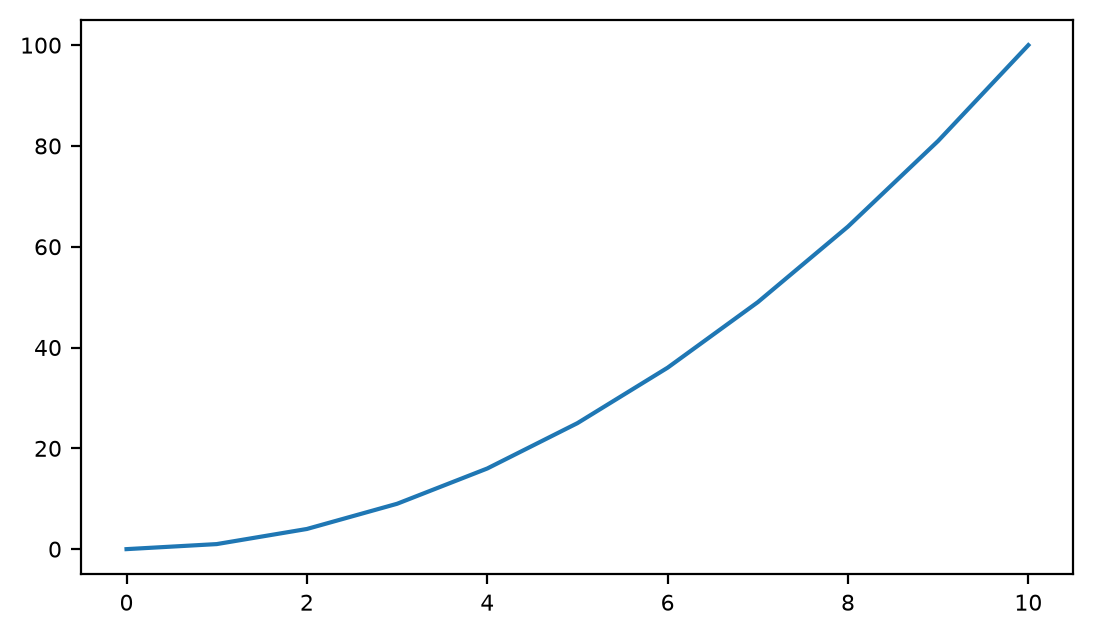

In [813]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2);

With `plt.grid()`, grid lines are drawn behind the data and values can be read from the axes with greater precision:

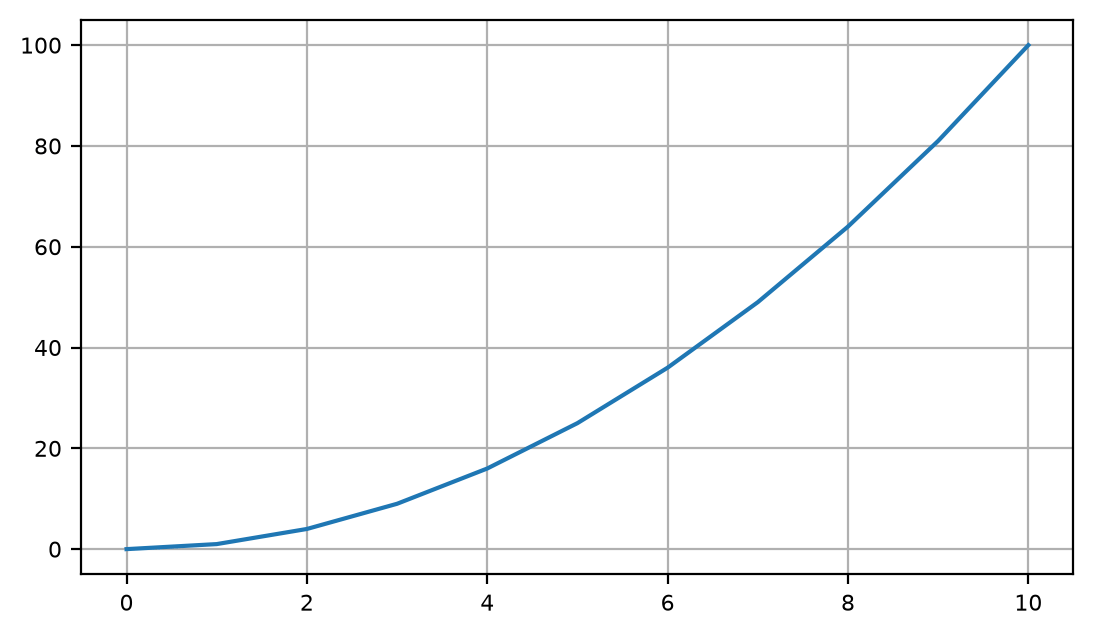

In [814]:
plt.plot(x, x ** 2)
plt.grid();

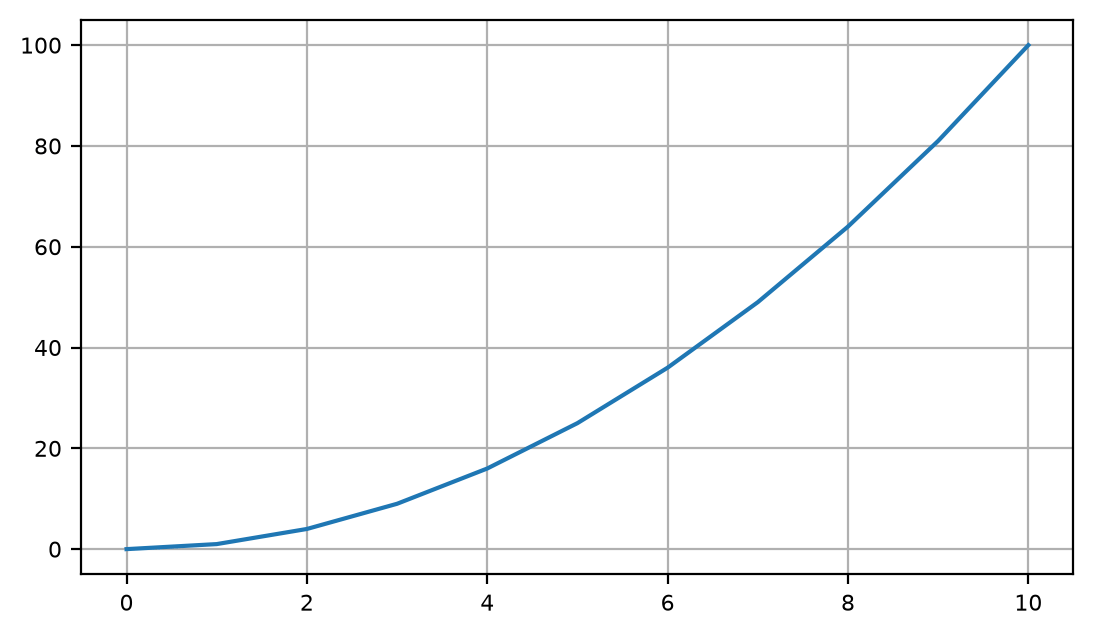

In [815]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(x, x ** 2)
ax.grid();

*See also:* Setting a seaborn theme (C3) · Setting axis limits (C1) · Choosing between `plt` and `ax` (C1)

#### Using a log scale

**C1.13**

`plt.yscale('log'), plt.xscale('log')`

The `plt.yscale('log')` and `plt.xscale('log')` functions allow us to use a logarithmic axis. It is useful for data spanning many orders of magnitude, or for checking exponential growth (a straight line). Alternatively, plot `np.log10(y)` and label the axis accordingly.

Exponential growth on a linear axis curves upwards sharply:

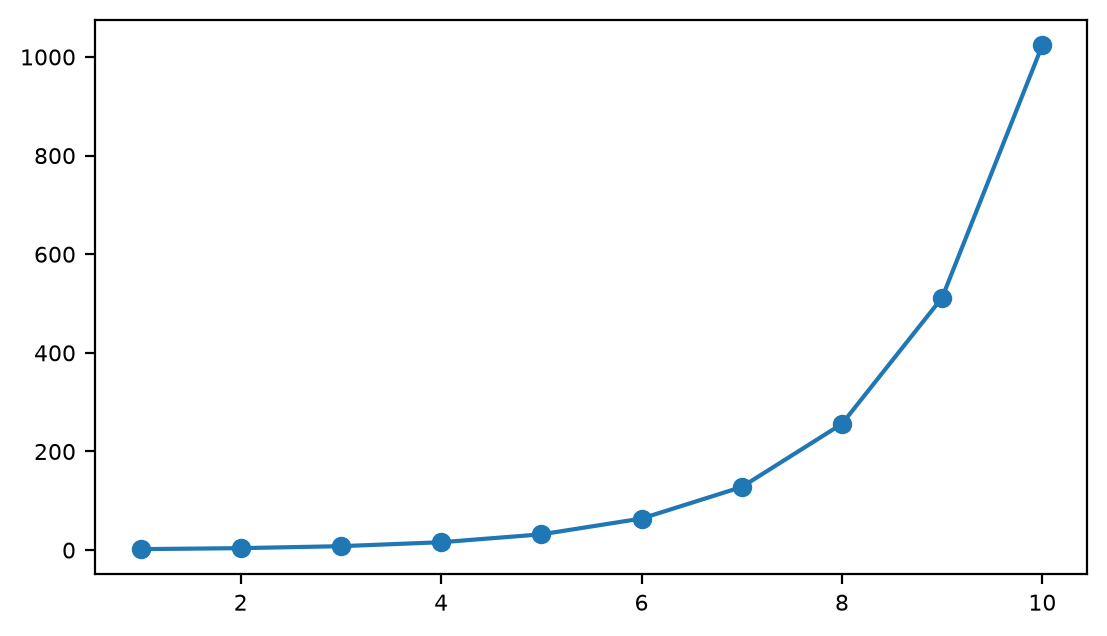

In [816]:
x = np.arange(1, 11)
y = 2.0 ** x            # exponential growth
plt.plot(x, y, "o-");

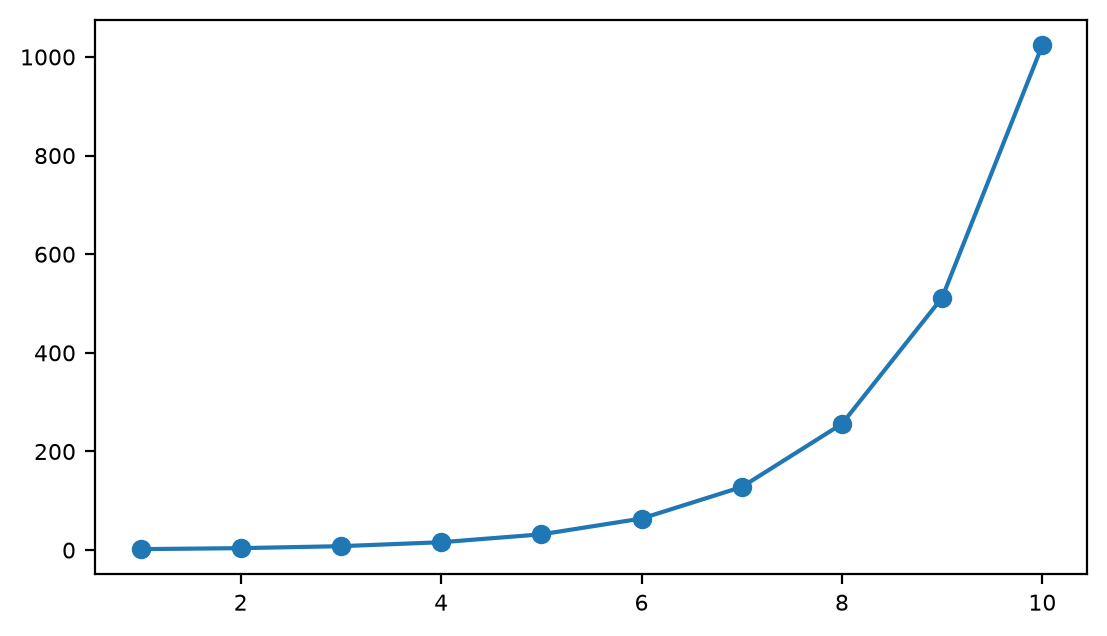

In [817]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(1, 11)
y = 2.0 ** x            # exponential growth
fig, ax = plt.subplots()
ax.plot(x, y, "o-");

On a logarithmic y axis the same data lie on a straight line:

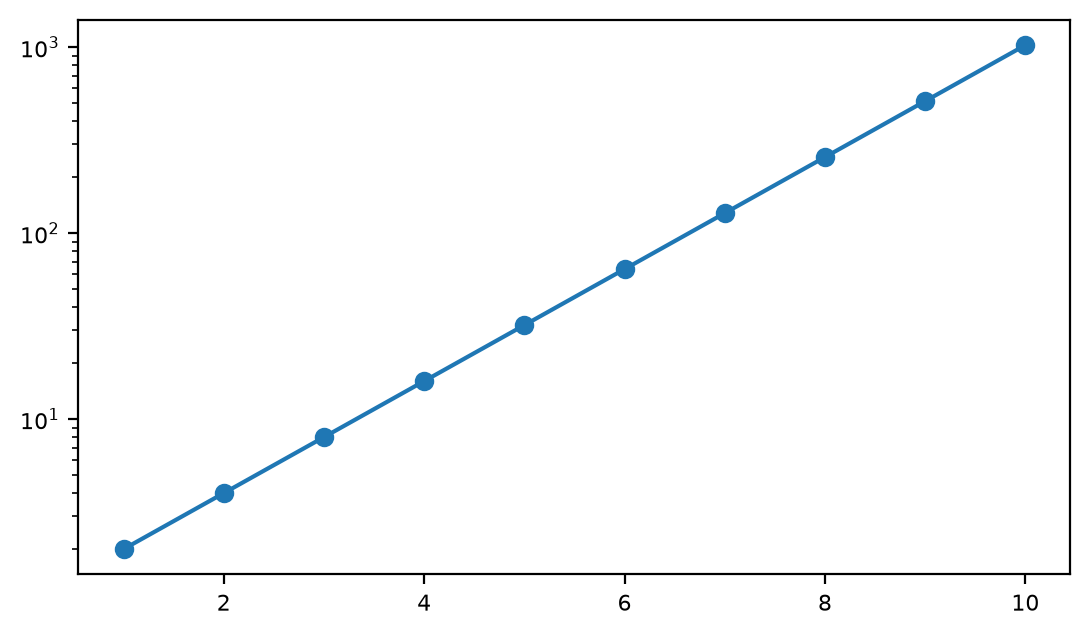

In [818]:
plt.plot(x, y, "o-")
plt.yscale("log");

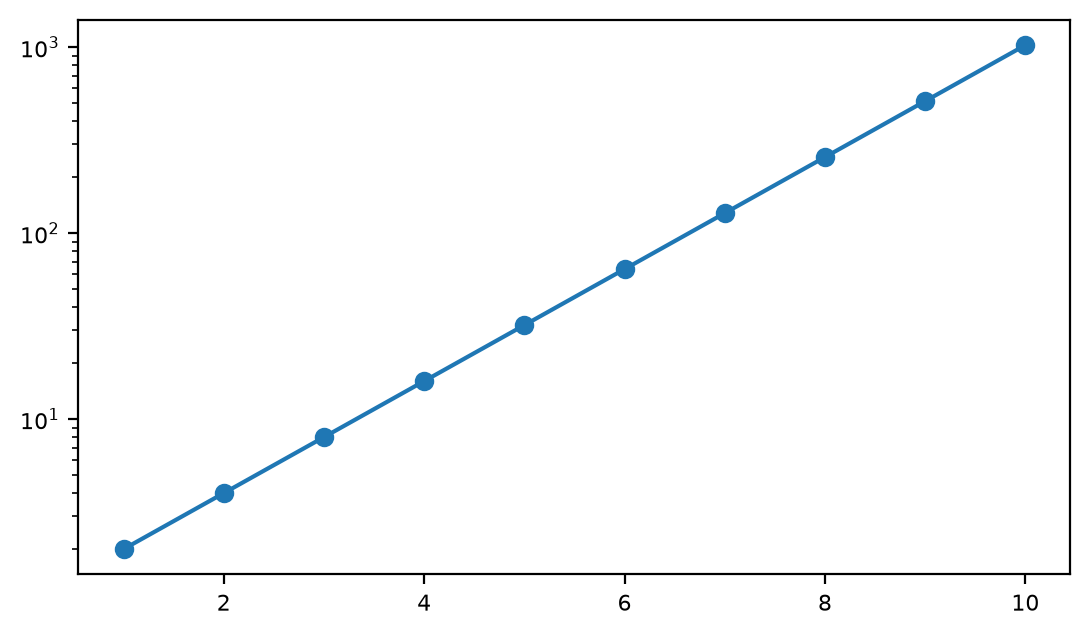

In [819]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(x, y, "o-")
ax.set_yscale("log");

*See also:* Log-log models (D5) · Applying maths functions to an array (A4) · Setting axis limits (C1)

### Reference lines

#### Drawing a horizontal line

**C1.14**

`plt.axhline(0, color='black', linestyle='--')`

The `plt.axhline()` function allows us to draw a horizontal line across the whole plot. It is useful for zero lines, targets or a carrying capacity. Alternatively, `plt.plot([x0, x1], [y, y])` draws a line between two chosen points.

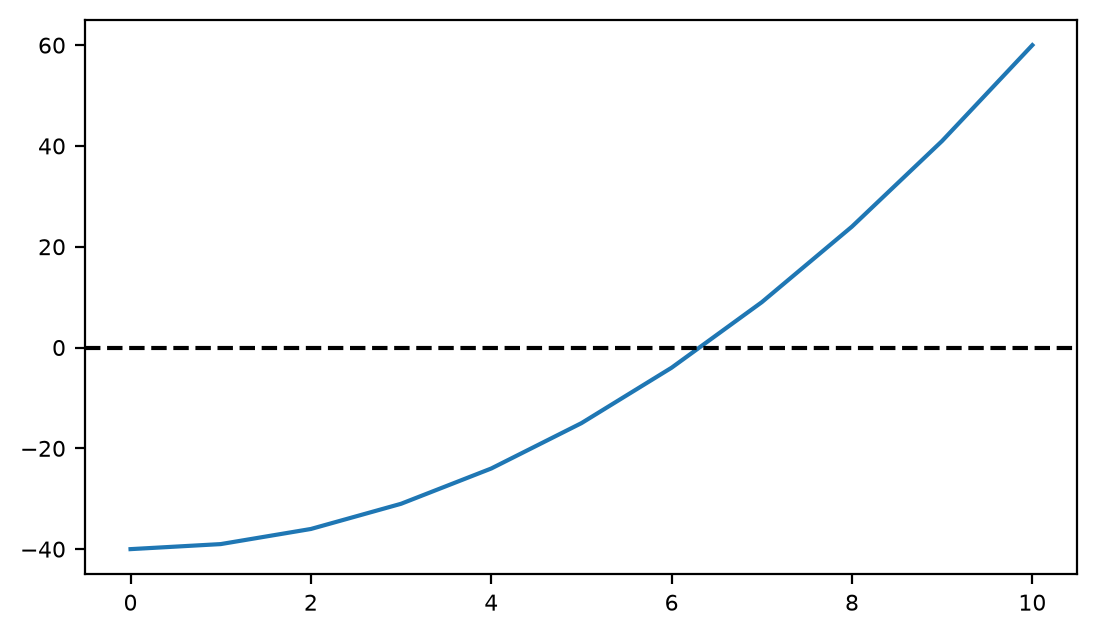

In [820]:
x = np.arange(0, 11)
plt.plot(x, x ** 2 - 40)
plt.axhline(0, color="black", linestyle="--");       # the zero line

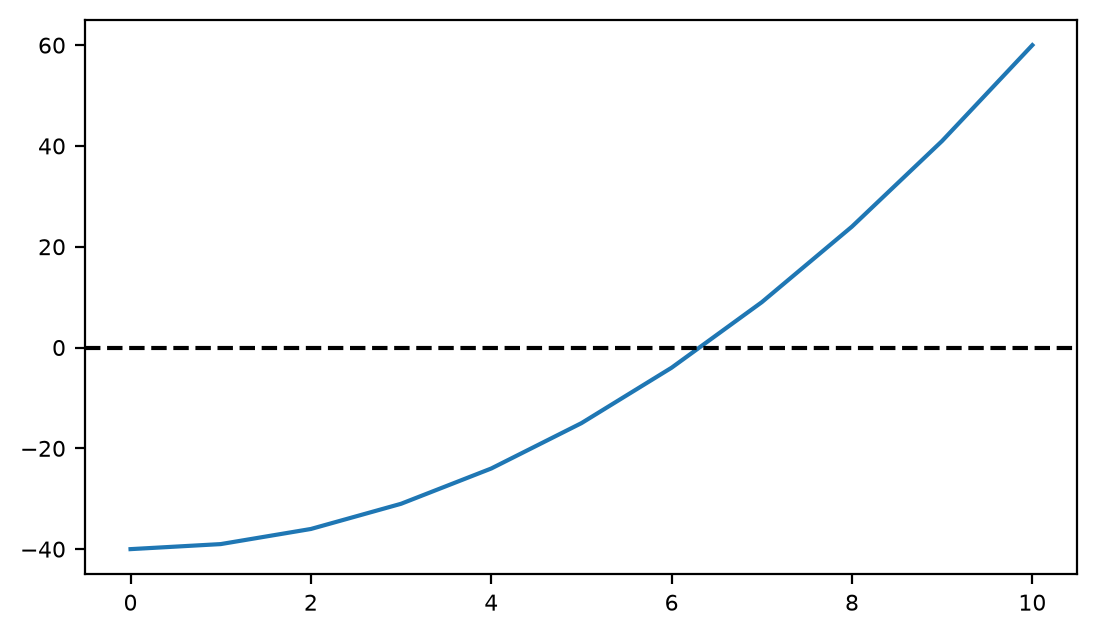

In [821]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2 - 40)
ax.axhline(0, color="black", linestyle="--");       # the zero line

*See also:* Drawing a vertical line (C1) · Residuals versus fitted values (D5)

#### Drawing a vertical line

**C1.15**

`plt.axvline(x)`

***(non-examinable)***

The `plt.axvline()` function allows us to draw a vertical line at a chosen x value. It is useful for marking a mean, a threshold or an observed value. Alternatively, `plt.axvspan` shades a whole range.

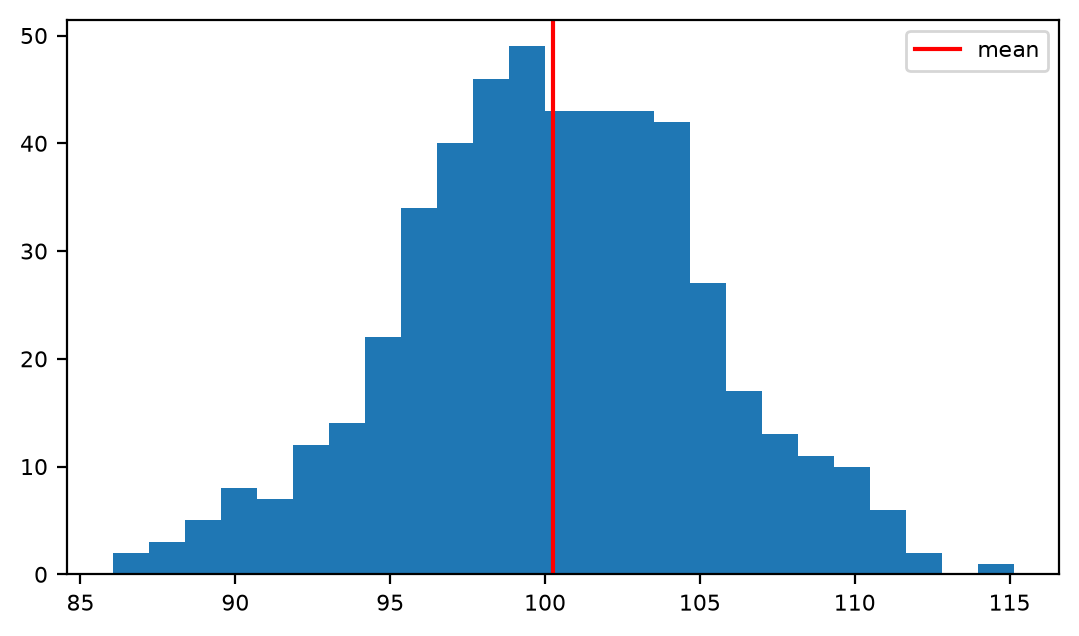

In [822]:
np.random.seed(1)                          # fixed seed, so the output is repeatable
data = np.random.normal(100, 5, 500)
plt.hist(data, bins=25)
plt.axvline(data.mean(), color="red", label="mean")
plt.legend();

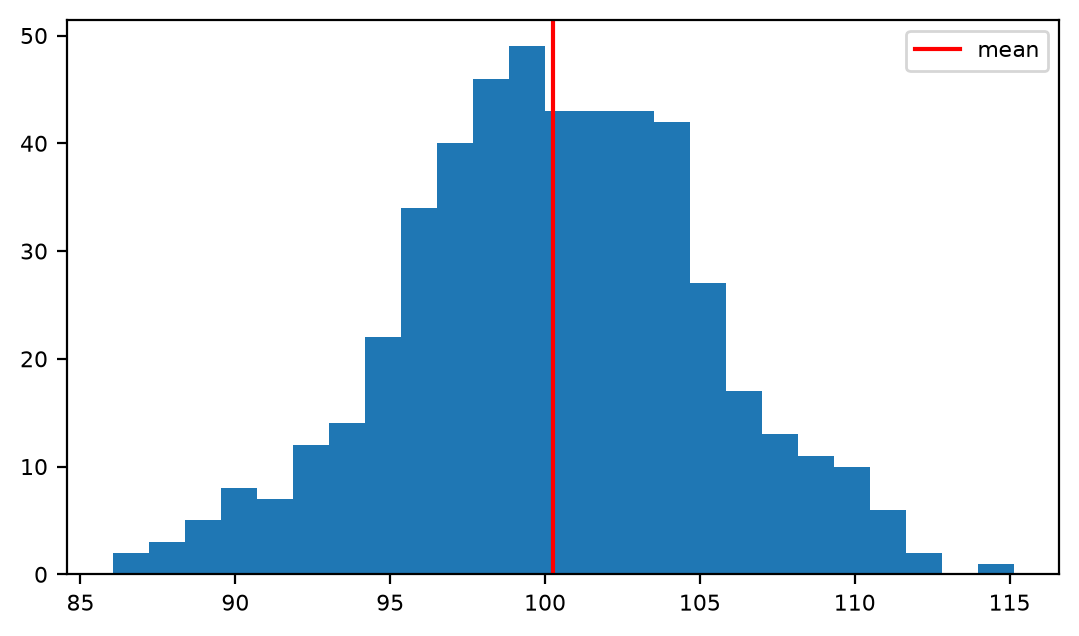

In [823]:
# the same plot in object-oriented style (ax. methods)
np.random.seed(1)                          # fixed seed, so the output is repeatable
data = np.random.normal(100, 5, 500)
fig, ax = plt.subplots()
ax.hist(data, bins=25)
ax.axvline(data.mean(), color="red", label="mean")
ax.legend();

*See also:* Shading a period (B8) · Drawing a horizontal line (C1) · Marking a date on a plot (B8) · Drawing a line y = mx + c (C1)

#### Drawing a line y = mx + c

**C1.16**

`plt.axline((0, c), slope=m)`

***(non-examinable)***

The `plt.axline` function allows us to draw a straight line of unlimited length through a point with a given slope. It is useful for adding a fitted line or a reference line `y = mx + c` to a plot. Alternatively, calculate `y = m * x + c` for an array of x values and draw the points with `plt.plot`.

For a line `y = 3x + 4`, the slope is `m = 3` and the intercept (the value of y where x = 0) is `c = 4`. Data that follow roughly this line are plotted first:

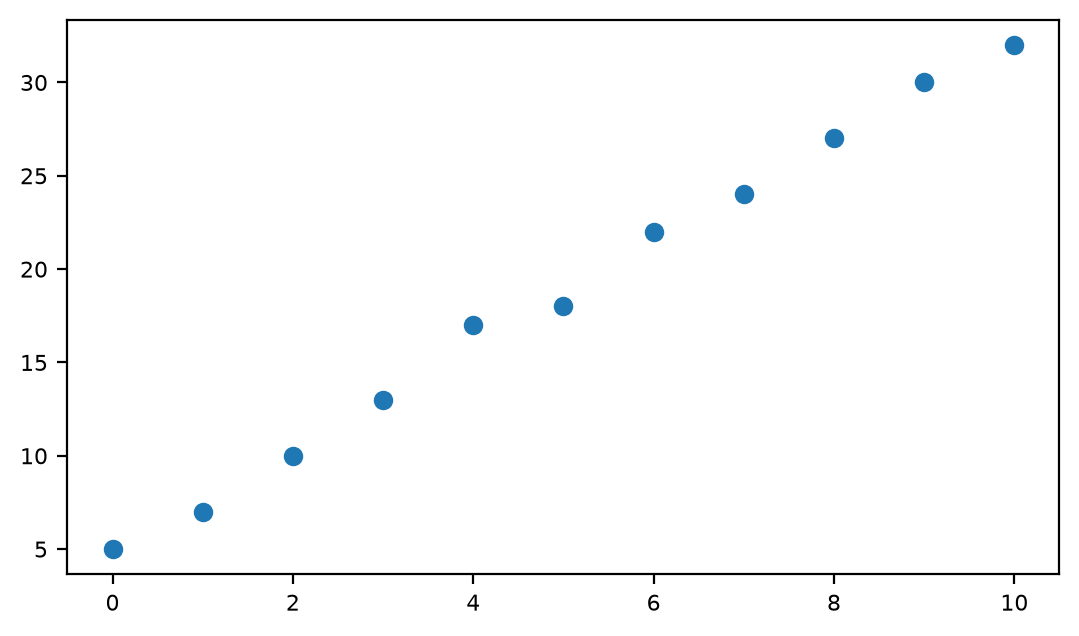

In [824]:
m, c = 3, 4
x = np.arange(0, 11)
y = np.array([5, 7, 10, 13, 17, 18, 22, 24, 27, 30, 32])
plt.scatter(x, y);

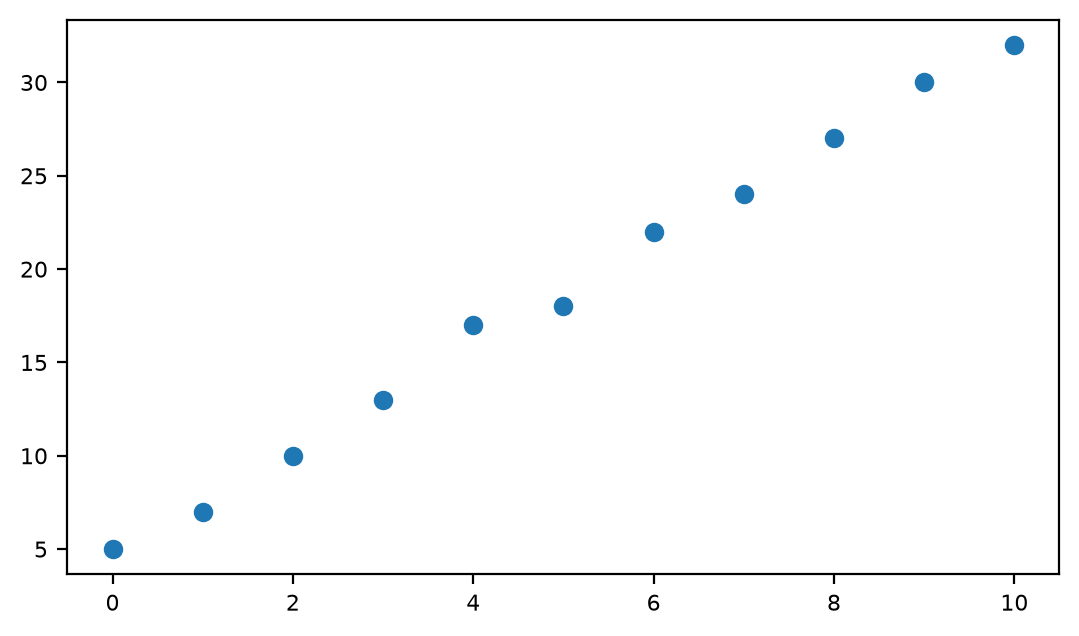

In [825]:
# the same plot in object-oriented style (ax. methods)
m, c = 3, 4
x = np.arange(0, 11)
y = np.array([5, 7, 10, 13, 17, 18, 22, 24, 27, 30, 32])
fig, ax = plt.subplots()
ax.scatter(x, y);

`axline` needs one point on the line and the slope:

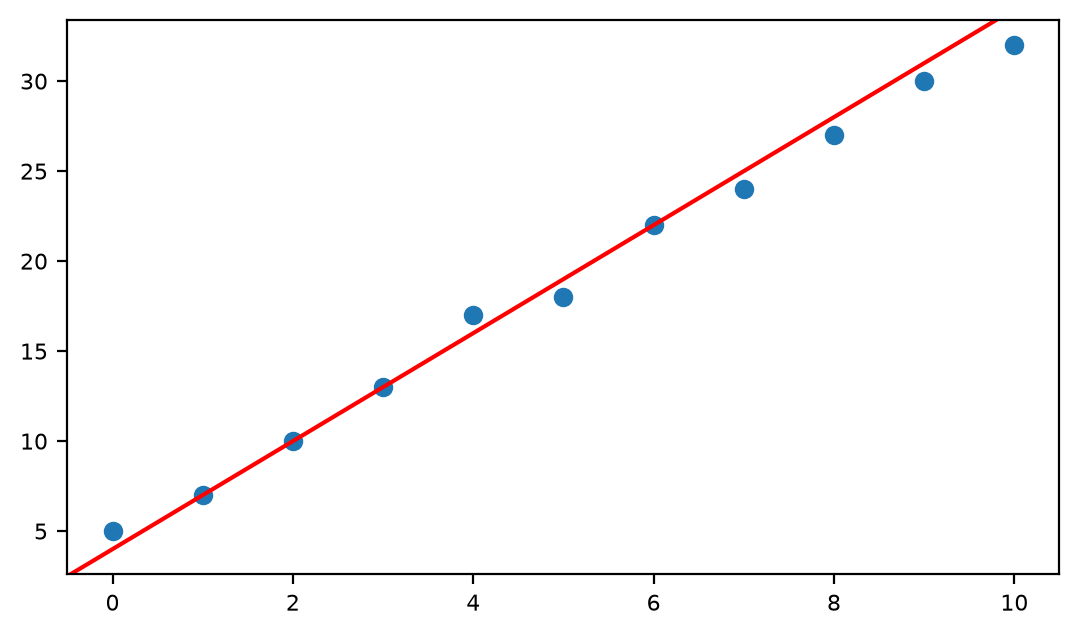

In [826]:
plt.scatter(x, y)
plt.axline((0, c), slope=m, color="red");      # through (0, 4) with slope 3

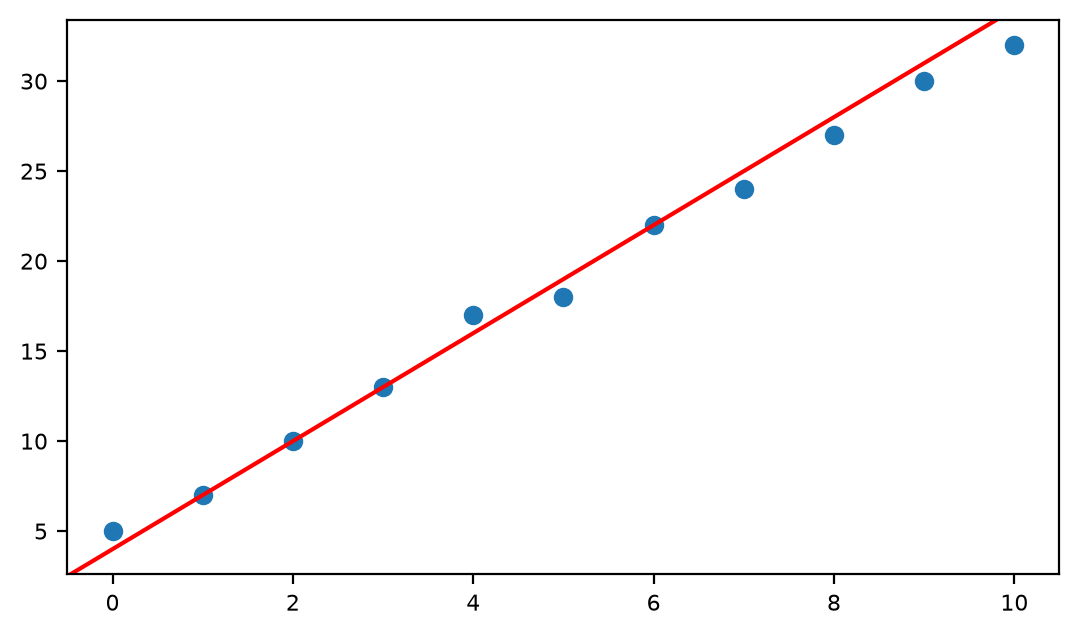

In [827]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.scatter(x, y)
ax.axline((0, c), slope=m, color="red");      # through (0, 4) with slope 3

A line through two chosen points can also be drawn, or `y = m * x + c` can be calculated for the x values and plotted:

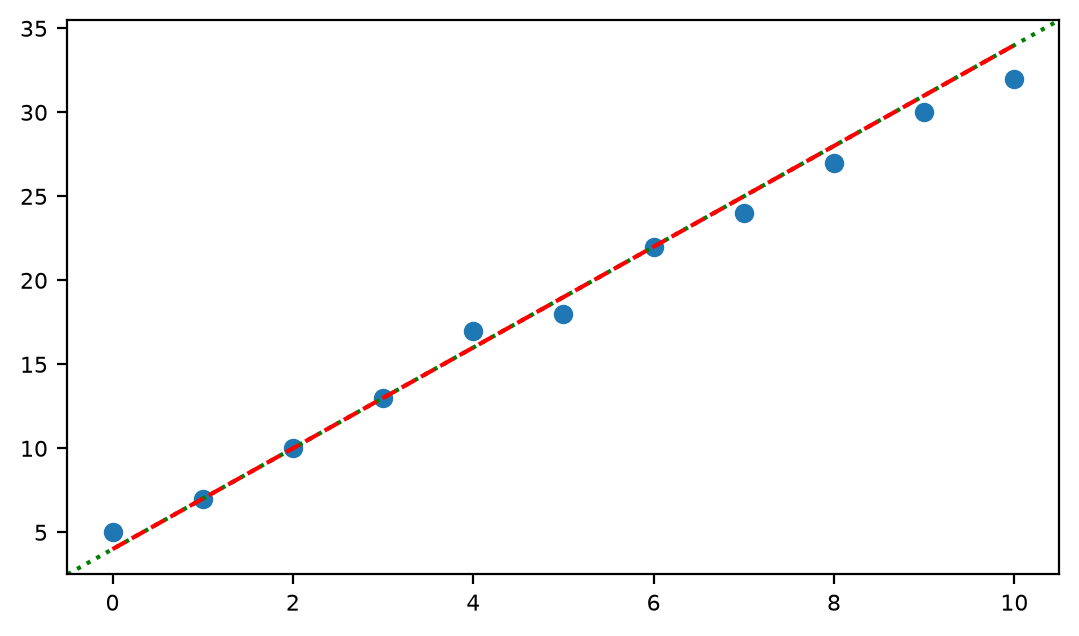

In [828]:
plt.scatter(x, y)
plt.axline((0, 4), (10, 34), color="green", linestyle=":")    # through two points
plt.plot(x, m * x + c, "r--");                                 # calculated from m and c

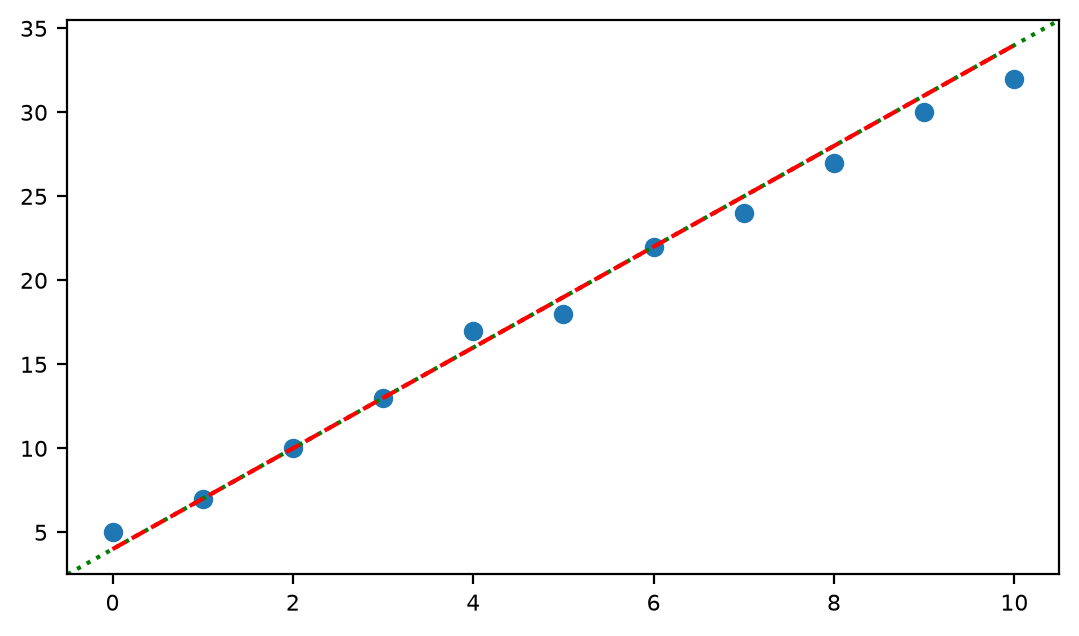

In [829]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.scatter(x, y)
ax.axline((0, 4), (10, 34), color="green", linestyle=":")    # through two points
ax.plot(x, m * x + c, "r--");                                 # calculated from m and c

*See also:* Drawing a horizontal line (C1) · Drawing a vertical line (C1) · Drawing a line between two points (C1) · Plotting a fitted line by hand (D5)

#### Drawing a line between two points

**C1.17**

`plt.plot([x0, x1], [y0, y1], 'r-')`

If we know two points on a line, then giving `plt.plot` two x values and two y values draws the segment between them. It is useful for drawing a fitted line from its end points. Alternatively, `sns.regplot` draws the fitted line automatically.

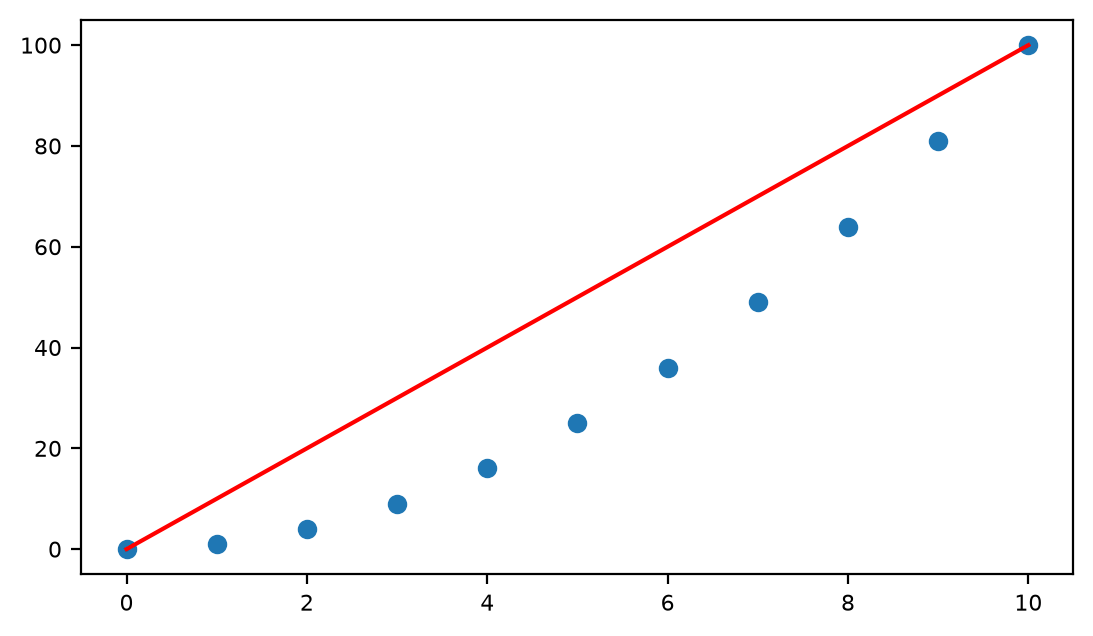

In [830]:
x = np.arange(0, 11)
y = x ** 2
plt.plot(x, y, "o")
plt.plot([0, 10], [0, 100], "r-");       # from (0, 0) to (10, 100)

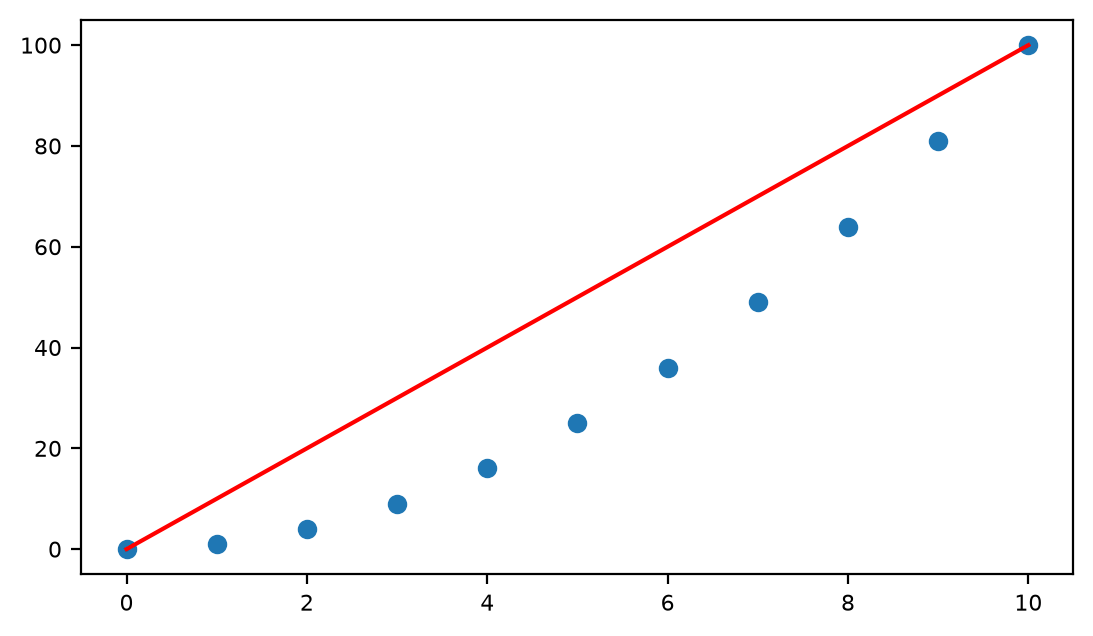

In [831]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
y = x ** 2
fig, ax = plt.subplots()
ax.plot(x, y, "o")
ax.plot([0, 10], [0, 100], "r-");       # from (0, 0) to (10, 100)

*See also:* Plotting a fitted line by hand (D5) · Drawing a scatter with a fitted line (C3)

### Figure settings

#### Setting figure size and resolution

**C1.18**

`plt.figure(figsize=(width, height), dpi=n)`

The `figsize` and `dpi` arguments of `plt.figure()` allow us to choose how big and how sharp a figure is. They are useful for fitting a figure into a report or making a slide readable. Alternatively, `plt.subplots(figsize=...)` sets the size when the axes are created.

The default size is set for the whole book (6.4 by 3.6 inches):

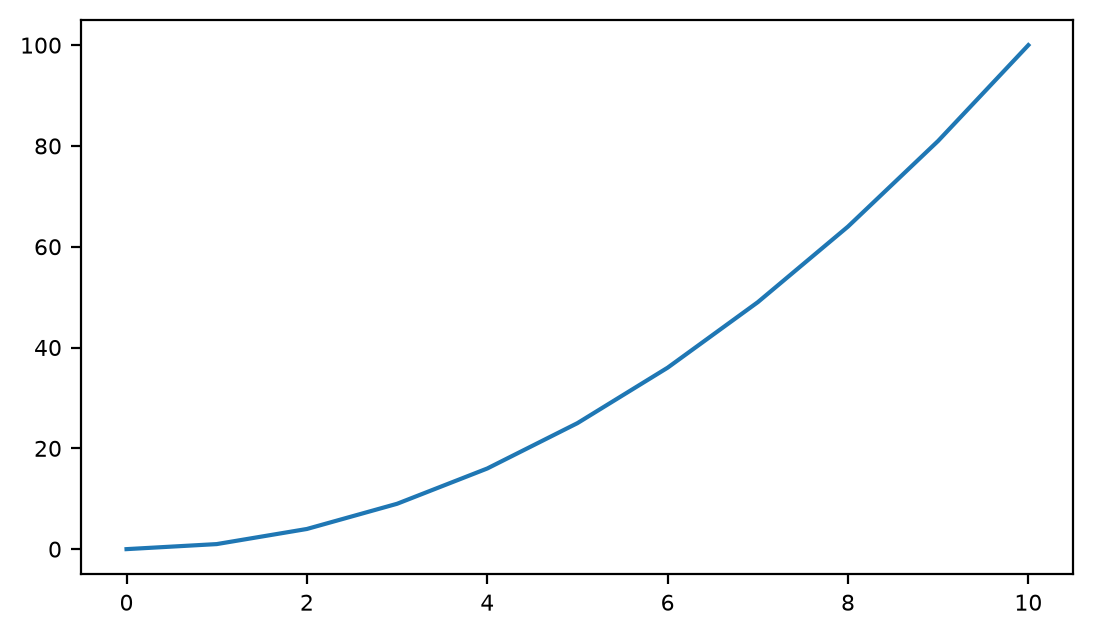

In [832]:
x = np.arange(0, 11)
plt.plot(x, x ** 2);

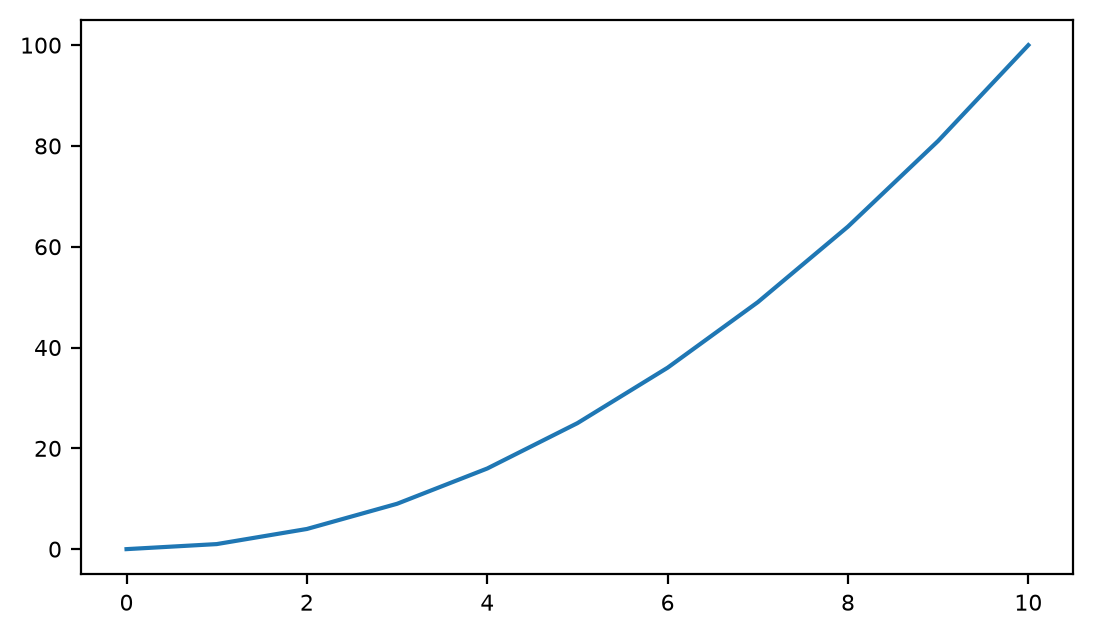

In [833]:
# the same plot in object-oriented style (ax. methods)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2);

`plt.figure(figsize=(width, height), dpi=...)` is called first to change the size of one figure (inches; `dpi` is the resolution):

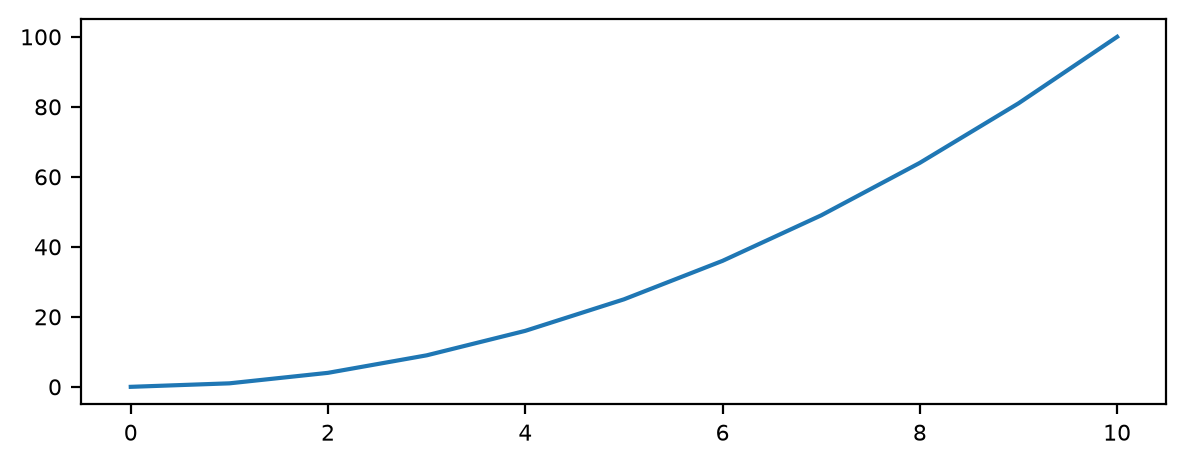

In [834]:
plt.figure(figsize=(7, 2.5), dpi=100)
plt.plot(x, x ** 2);

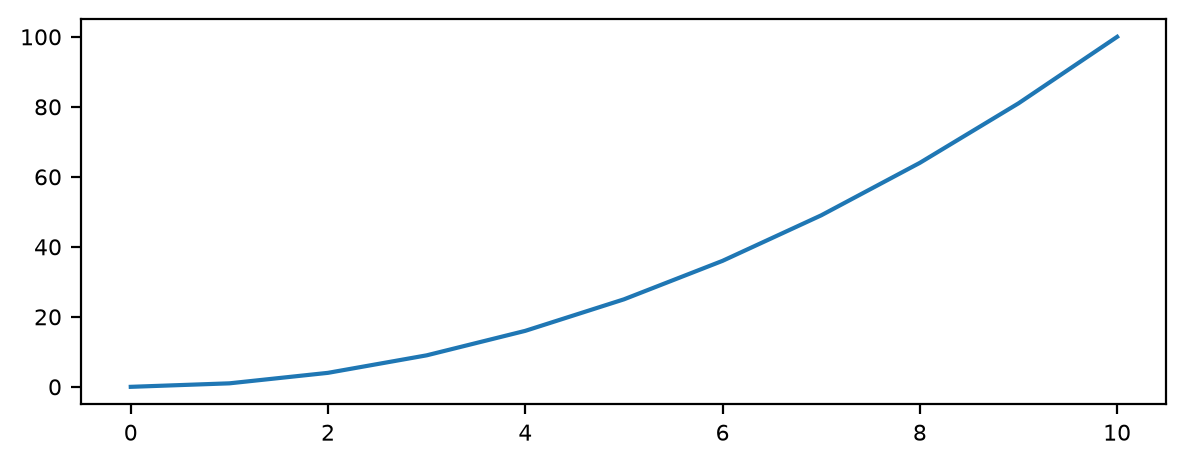

In [835]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots(figsize=(7, 2.5), dpi=100)
ax.plot(x, x ** 2);

*See also:* Changing the plot defaults (C1) · Drawing panels with `plt.subplots` (C2) · Saving a figure (C1)

#### Changing the plot defaults

**C1.19**

`plt.rcParams['figure.figsize'] = (width, height)`

The `plt.rcParams` dictionary allows us to change default settings, such as figure size, for every later plot. It is useful at the top of a notebook so that settings are not repeated. Alternatively, set the size on each figure individually.

In [836]:
plt.rcParams["figure.figsize"]            # the current default size (width, height) in inches

[6.4, 3.6]

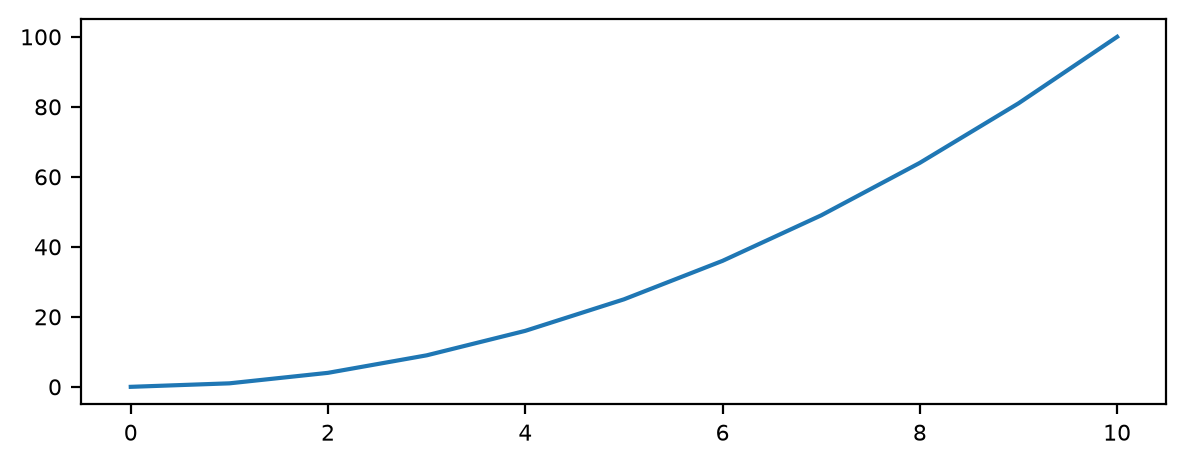

In [837]:
plt.rcParams["figure.figsize"] = (7, 2.5)
x = np.arange(0, 11)
plt.plot(x, x ** 2);

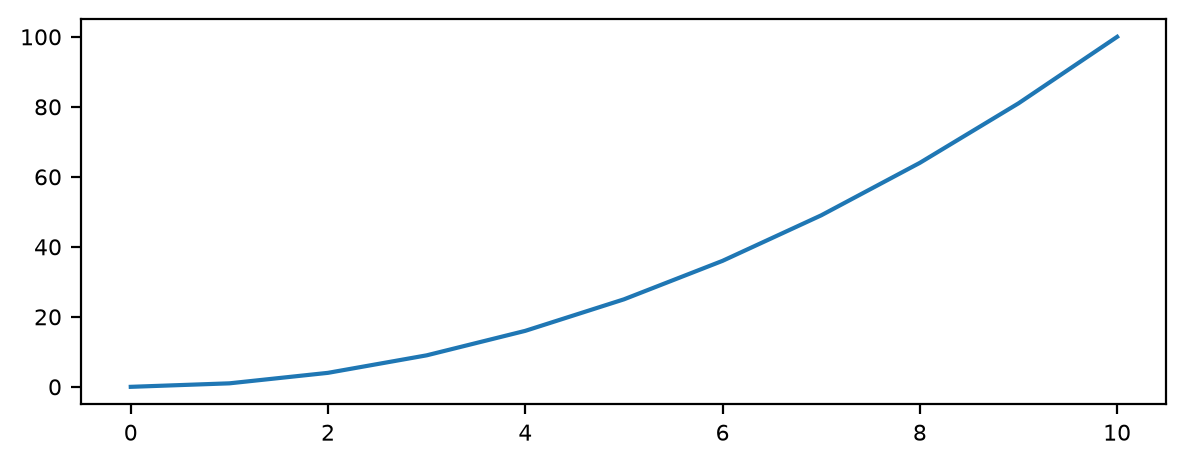

In [838]:
# the same plot in object-oriented style (ax. methods)
plt.rcParams["figure.figsize"] = (7, 2.5)
x = np.arange(0, 11)
fig, ax = plt.subplots()
ax.plot(x, x ** 2);

In [839]:
plt.rcParams["figure.figsize"] = (6.4, 3.6)    # put the default back
plt.rcParams["figure.figsize"]

[6.4, 3.6]

*See also:* Setting figure size and resolution (C1) · Passing plot options as a dictionary (A3) · Finishing a figure with `plt.show()` (C1)

#### Finishing a figure with `plt.show()`

**C1.20**

`plt.show()`

The `plt.show()` function allows us to finish the current figure, so the next plotting commands start a fresh one. It is useful when one cell draws several plots that must stay separate. Alternatively, a trailing semicolon hides the text output but does not separate figures.

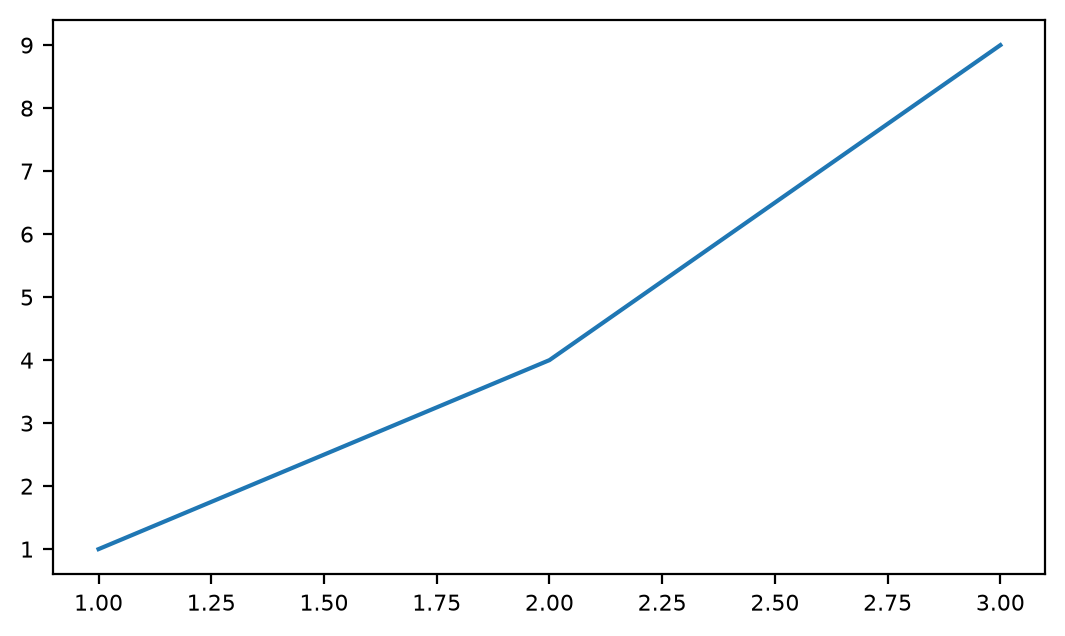

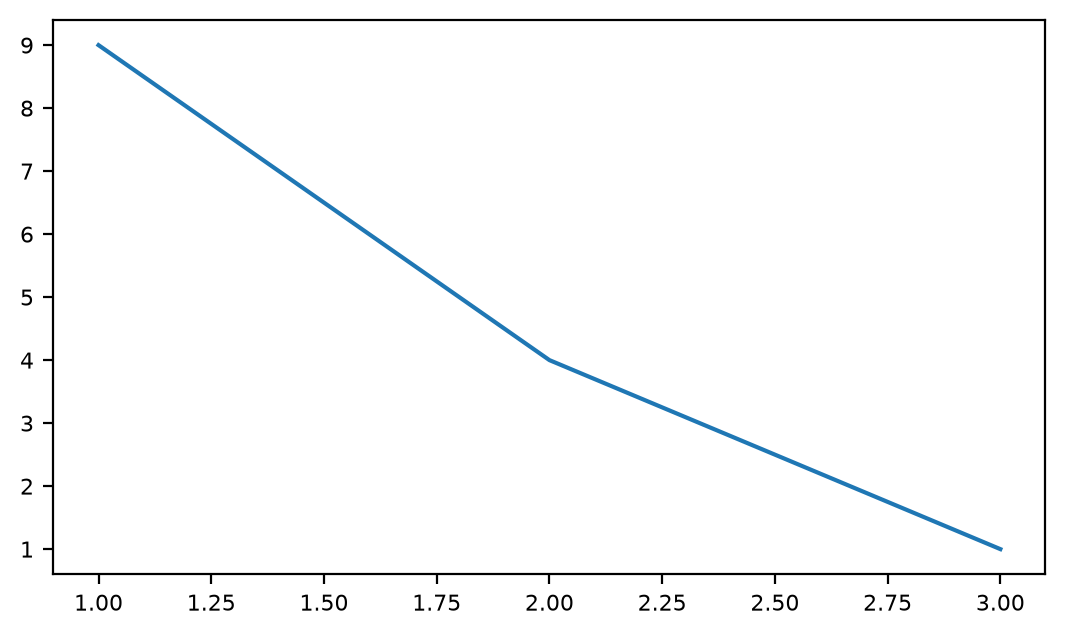

In [840]:
plt.plot([1, 2, 3], [1, 4, 9])
plt.show()                          # figure 1 ends here
plt.plot([1, 2, 3], [9, 4, 1])
plt.show()                          # figure 2

*See also:* Hiding the text output of a plot (A1) · Drawing panels with `plt.subplot` (C2) · Saving a figure (C1)

#### Saving a figure

**C1.21**

`plt.savefig('file.png', dpi=n, bbox_inches='tight')`

***(non-examinable)***

The `plt.savefig()` function allows us to write a plot to an image file. It is useful for including figures in a report or slides. Alternatively, right-click the plot in Jupyter and "Save image as", but that is less repeatable.

Call `savefig` **before** `plt.show()`, otherwise the file is blank.

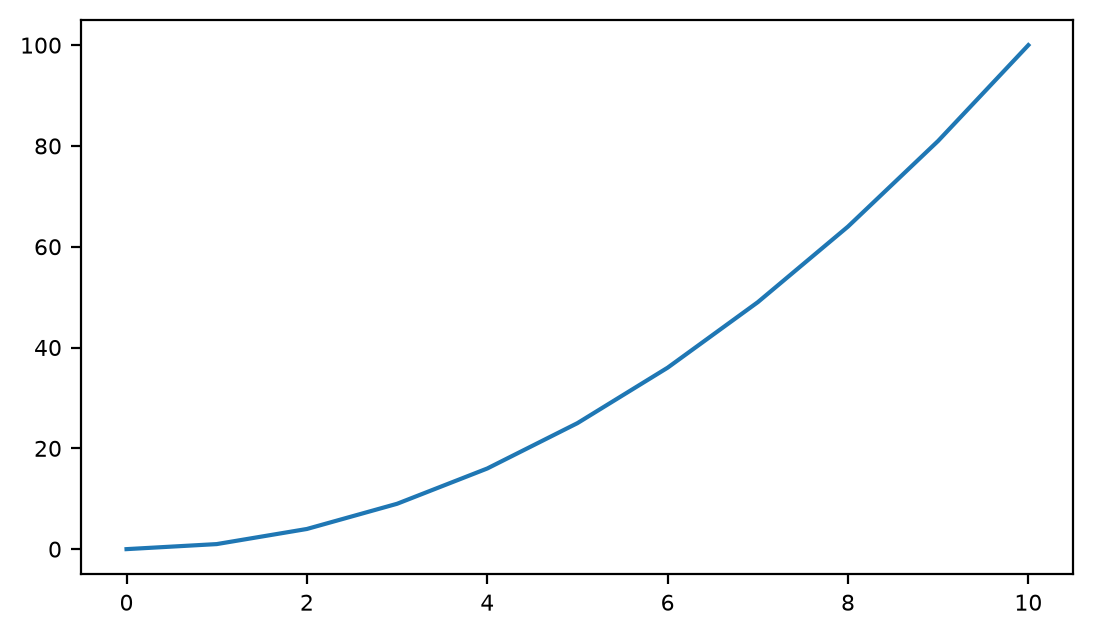

saved: True


In [841]:
x = np.arange(0, 11)
plt.plot(x, x ** 2)
plt.savefig("fig.png", dpi=300, bbox_inches="tight")
plt.show()
import os
print(f'saved: {os.path.exists("fig.png")}')

*See also:* Setting figure size and resolution (C1) · Changing the plot defaults (C1) · Finishing a figure with `plt.show()` (C1)

#### Making points or lines transparent

**C1.22**

`alpha=0.5`

***(non-examinable)***

The `alpha=` argument allows us to make a plot element partly see-through (0 = invisible, 1 = solid). It is useful when many points overlap, because dense areas then look darker. Alternatively, smaller markers (`s=`) reduce overlap too.

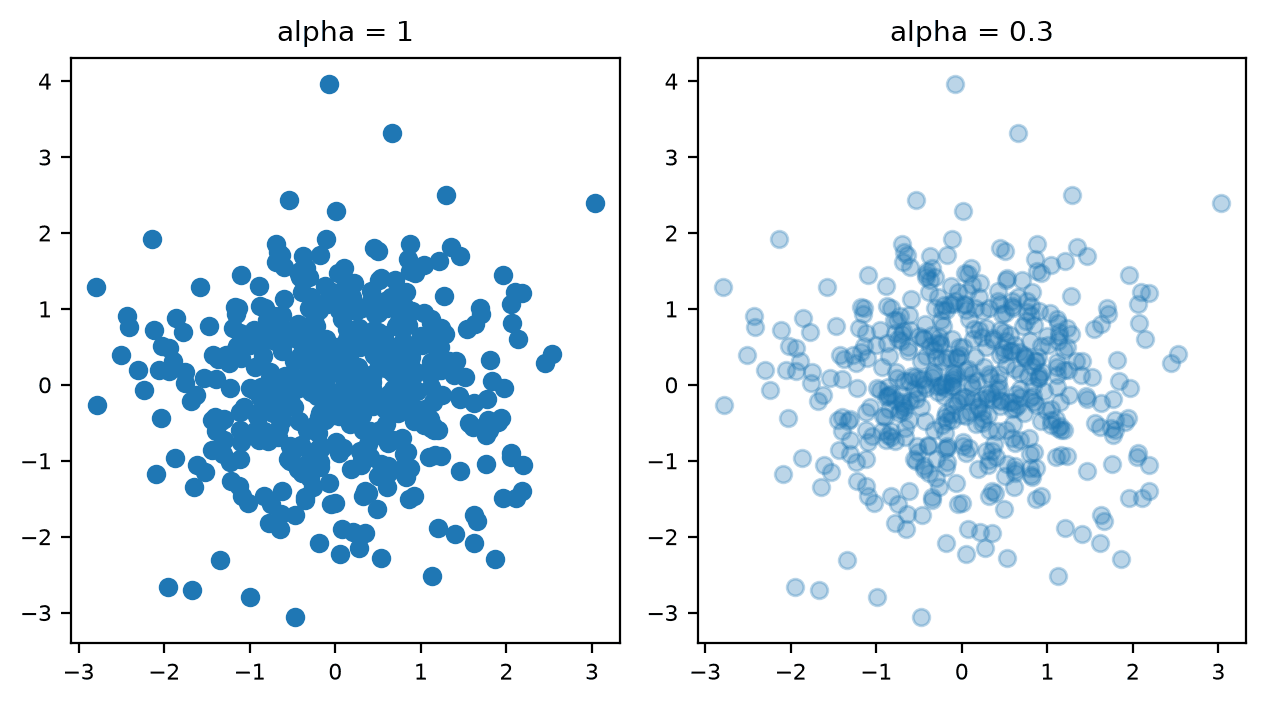

In [842]:
np.random.seed(1)                          # fixed seed, so the output is repeatable
x = np.random.normal(size=500)
y = np.random.normal(size=500)
plt.subplot(1, 2, 1); plt.scatter(x, y); plt.title("alpha = 1")
plt.subplot(1, 2, 2); plt.scatter(x, y, alpha=0.3); plt.title("alpha = 0.3")
plt.tight_layout();

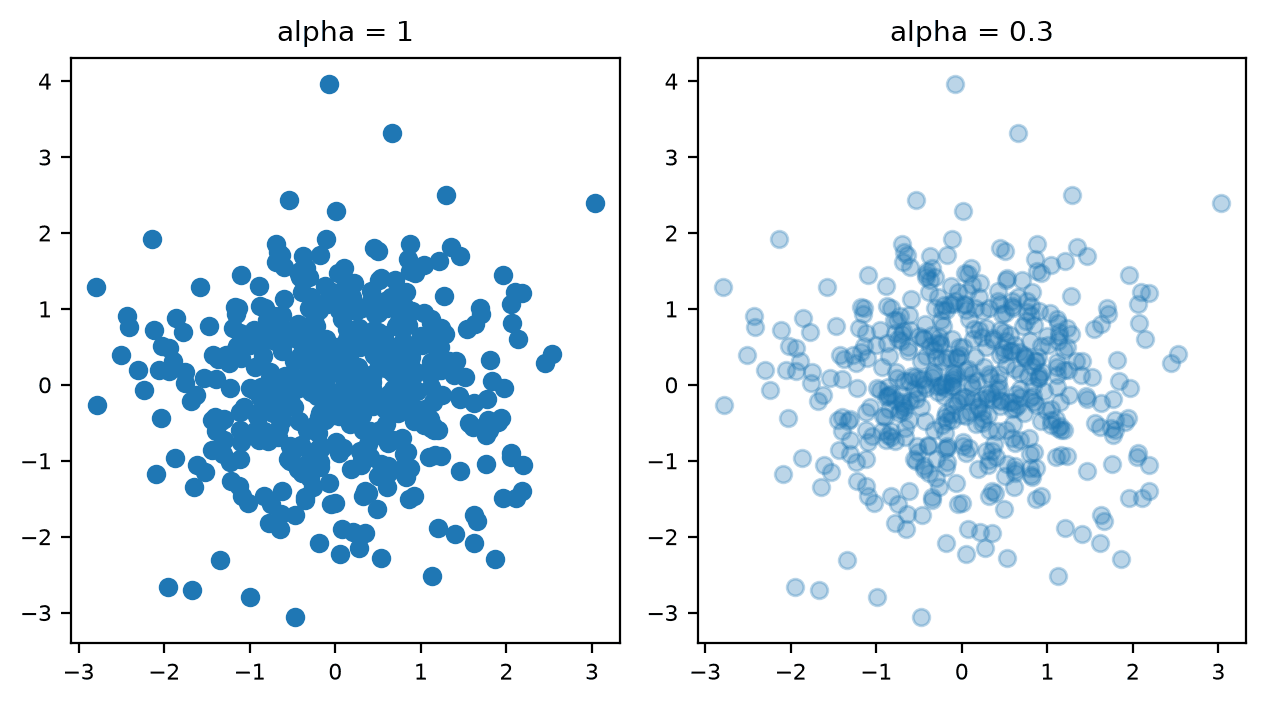

In [843]:
# the same plot in object-oriented style (ax. methods)
np.random.seed(1)                          # fixed seed, so the output is repeatable
x = np.random.normal(size=500)
y = np.random.normal(size=500)
fig, axs = plt.subplots(1, 2)
ax = axs[0]; ax.scatter(x, y); ax.set_title("alpha = 1")
ax = axs[1]; ax.scatter(x, y, alpha=0.3); ax.set_title("alpha = 0.3")
fig.tight_layout();

*See also:* Styling a line with keyword arguments (C1) · Drawing a scatter plot (C2)